# **Project #22 · MIMO CSI Feedback Compression with Autoencoders**

**Project ID: 22** · Group 3 · Level A (Advanced) · NVIDIA Sionna & synthetic PHY datasets

*A user equipment (UE) measures its 8×8 downlink channel **H**, squeezes it into a short codeword **z**, and the base station (gNB) rebuilds **Ĥ**. How far can we compress before the channel becomes useless?*

| | |
|---|---|
| **Data** | 5,000 ray-traced channels per city (**Munich** and **Bologna**). Each 8×8 complex **H** is stored as a 2×8×8 real tensor (Re/Im), i.e. **D = 128** real values |
| **Task** | UE encoder $z=f_\theta(H)\in\mathbb R^{d}$, gNB decoder $\hat H=g_\phi(z)$, with $d\in\{32,16,8\}$ → compression **4×, 8×, 16×** |
| **Loss** | $\mathcal L_{CSI}=\frac1N\sum_{i}\lVert H^{(i)}-\hat H^{(i)}\rVert_F^2$ |
| **Models** | Dense **MLP** vs. residual **2D-CNN**, plus a linear **PCA** baseline |
| **Deliverables** | **1.** side-by-side heatmaps $\lvert H\rvert$ vs. $\lvert\hat H\rvert$ for each ratio · **2.** NMSE (dB) vs. compression ratio $D/d$, MLP vs. CNN |

### Roadmap
1. The problem in nine slides (animation) → 2. Setup → 3. Configuration → 4. The two urban scenes → 5. From ray tracing to a CSI dataset → 6. What a CSI matrix looks like → 7. The autoencoders → 8. Loss and KPIs → 9. Training and PCA baseline → 10. KPI tables → **11. Deliverable 1** → **12. Deliverable 2** → 13. Munich vs. Bologna → 14. Critical diagnostics → 15. Limitations → 16. Conclusion.
Appendices: A. building the Bologna scene, B. glossary.

### What is recomputed live, and what is loaded?
Ray tracing (minutes) and training of the 12 autoencoders (≈ 4 min per city) are **not** meant to be redone during the oral. They are run once beforehand (switches in section 2), and their products are read back:

| | Source | Examples |
|---|---|---|
| **Live** (seconds) | recomputed here | data loading, splits, PCA baseline, KPI functions, model sizes, Deliverable 2 curves, city comparison, a 15-epoch training demo |
| **Archived** | `data/` and `results/` from my runs | CSI caches (`*_csi_5000.npz`), KPI CSVs, heatmaps, learning curves, 3D renders, diagnostics |
| **Re-run** | switches in the `RUN` dictionary (section 2) | ray tracing, 3D renders, full training of one city or both (figures and KPI tables are saved in `results/`, a previous file being kept as `.bak`; a re-generated dataset never overwrites `data/`) |

## **1 · The problem in nine slides**

Interactive animation, loaded from `Intro to the Problem Simulation.html` (same folder as this notebook). Click inside it, then use the arrow keys or the dots. In short:

| Slides | Idea |
|---|---|
| 1–3 | A massive-MIMO gNB can **beamform** (focus energy on one UE, saving energy), but only if it *knows where the UE is*: it needs the channel. |
| 4 | In a city the signal reaches the UE through many **reflections** (multipath), whose phases depend on the carrier frequency. |
| 5 | In **FDD** the uplink and downlink use different frequencies, so the gNB cannot infer the downlink channel from what it hears: the **UE must measure it and feed it back**. An 8×8 link has 64 coefficients, hence **128 real numbers** per snapshot. |
| 6–7 | The channel changes as the UE moves, so the feedback must be repeated often; with many UEs, it **drains batteries and congests the uplink**. |
| 8–9 | **Autoencoder**: the UE compresses **H** into a short codeword, the gNB rebuilds **Ĥ ≈ H**. This is the project. |

> Note on the representation. To keep the drawing readable, the animation shows each link as "power + delay" (2 values per link). In the actual pipeline the 2 values per link are the **real and imaginary parts** of the complex coefficient. The count (64 × 2 = 128) is the same.

In [28]:
import html
from pathlib import Path
from IPython.display import HTML, display

INTRO_FILE = next((p for p in [Path("Intro to the Problem Simulation.html"), Path("Intro_to_the_Problem_Simulation.html")] if p.exists()), None)


def show_intro_animation(height: int = 680) -> None:
    """Render the HTML animation (a self-contained file at the project root) inside an iframe."""
    if INTRO_FILE is None:
        print(f"Animation file not found in {Path.cwd()}: put 'Intro to the Problem Simulation.html' next to the notebook.")
        return
    doc = INTRO_FILE.read_text(encoding="utf-8")
    display(HTML(f'<iframe srcdoc="{html.escape(doc, quote=True)}" '
                 f'style="width:100%;height:{height}px;border:1px solid #888;border-radius:8px"></iframe>'))
    print(f"Animation loaded from {INTRO_FILE}. If the frame stays blank, open that file in a browser.")


show_intro_animation()

/Users/user/Documents/ESIEE/E3/Bologne/Project Big Data/.venv/lib/python3.11/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Animation loaded from Intro to the Problem Simulation.html. If the frame stays blank, open that file in a browser.


## **2 · Setup**

Libraries and run switches (which cities to ray-trace, render and train). **Sionna RT** (built on Mitsuba 3 / Dr.Jit) is only needed to *regenerate* radio data; if it is missing, the notebook still runs on the archived data. **PyTorch** picks CUDA, Apple-Silicon MPS or CPU automatically.

In [29]:
import re, shutil, time
from dataclasses import dataclass, field, replace
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import HTML, Image, Markdown, display

%matplotlib inline
# Opaque white canvas with black text: without it, figures are transparent in dark themes and
# legends, axis labels and tick labels become invisible.
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "facecolor": "white"}

# Sionna RT is optional: only the ray-tracing sections need it.
try:
    import mitsuba as mi
    import sionna.rt
    from sionna.rt import Camera, PathSolver, PlanarArray, RadioMapSolver, Receiver, Transmitter, load_scene
    SIONNA_OK = True
except ImportError:
    SIONNA_OK = False

# --------------------------------------------------------------------------------------------
# Run switches. Set the heavy ones to False to rely only on what is already stored in data/ and results/.
# --------------------------------------------------------------------------------------------
SCENES = ["munich", "bologna"]
SEED = 42

RUN = {
    "ray_tracing": True,   # re-run Sionna RT for RAY_TRACE_SCENES, write the NEW datasets to results/live/ (long)
    "renders":     True,   # re-render the 3D views of RENDER_SCENES with Sionna RT
    "training":    True,   # re-train the 12 autoencoders of every city in TRAIN_SCENES (~4 min per city on Apple GPU)
    "quick_demo":  True,  # 15-epoch training of MLP and CNN at d=16 (~10-30 s): shows the training loop live
}
# Which city for each heavy step: "munich", "bologna" or "both" (a list such as ["munich"] also works).
RAY_TRACE_SCENES = "both"
RENDER_SCENES = "both"
TRAIN_SCENES = "both"
DEMO_EPOCHS = 15

# Figure cache: every figure is looked up in results/ first. A figure that is missing is drawn, then saved there.
# True = ignore the cached PNGs and redraw every figure that can be redrawn (the previous file is kept as .bak).
REGENERATE_FIGURES = False


def resolve_scenes(choice) -> List[str]:
    """'both' / 'all' -> every scene; 'munich' -> ['munich']; a list is checked and returned."""
    if isinstance(choice, str):
        choice = SCENES if choice.lower() in ("both", "all") else [choice.lower()]
    unknown = [c for c in choice if c not in SCENES]
    if unknown:
        raise ValueError(f"Unknown scene(s) {unknown}; choose from {SCENES} or 'both'")
    return list(choice)


RAY_TRACE_SCENES, RENDER_SCENES, TRAIN_SCENES = map(resolve_scenes, (RAY_TRACE_SCENES, RENDER_SCENES, TRAIN_SCENES))

# Colours used for every figure: one colour per model.
COLORS = {"CNN": "#2B7A78", "MLP": "#D9534F", "PCA": "#6C757D"}
MODEL_LABEL = {"CNN": "2D-CNN", "MLP": "Dense MLP", "PCA": "Linear PCA"}


def set_seed_and_device(seed: int = SEED) -> torch.device:
    """Fix every random seed and return the best available PyTorch device."""
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    try:  # NNPACK slows down multi-core CPU runs on Apple Silicon
        torch.backends.nnpack.set_flags(False)
    except Exception:
        pass
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


plt.rcParams.update({
    "figure.facecolor": "white", "savefig.facecolor": "white", "axes.facecolor": "#F8F9FA", "axes.edgecolor": "#888888",
    "text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black",
    "xtick.color": "black", "ytick.color": "black", "xtick.labelcolor": "black", "ytick.labelcolor": "black",
    "axes.grid": True, "grid.color": "#E5E7EB", "grid.linestyle": "--", "grid.linewidth": 0.6,
    "font.size": 10.0, "axes.titlesize": 11.5, "axes.labelsize": 10.5, "legend.framealpha": 0.92,
    "figure.dpi": 100,
})


def save_with_backup(path: Path, writer) -> None:
    """Write a file with writer(path); an existing file is first copied to <name>.bak (kept once)."""
    path.parent.mkdir(parents=True, exist_ok=True)
    backup = path.with_name(path.name + ".bak")
    if path.exists() and not backup.exists():
        shutil.copy2(path, backup)
    writer(path)


def cached_figure(draw, target: Path, found: Optional[Path] = None, force: bool = False,
                  can_draw: bool = True, show: bool = True, width: int = 1200) -> None:
    """Figure cache. Show the cached PNG when it exists; otherwise call draw() (returns a figure), save it to `target`, show it.

    found : existing cached file to display (defaults to `target` if it exists)
    force : redraw even if cached (also forced by REGENERATE_FIGURES), e.g. because the data was just recomputed
    can_draw : False when the data needed to draw is not available (then only a cached file can be shown)
    show : False to only (re)write the cache without displaying
    """
    found = found if found is not None else (target if target.exists() else None)
    redraw = REGENERATE_FIGURES or force
    if found is not None and not (redraw and can_draw):
        if show:
            display(Image(filename=str(found), width=width))
        return
    if not can_draw:
        print(f"Figure not available: {target.name} (not cached and nothing to draw it from)")
        return
    fig = draw()
    save_with_backup(target, lambda p: fig.savefig(p, dpi=150, bbox_inches="tight", facecolor="white"))
    if show:
        plt.show()
    else:
        plt.close(fig)
    print(f"saved to cache: {target}")

device = set_seed_and_device(SEED)
print(f"PyTorch {torch.__version__} | device: {device} | seed: {SEED}")
print("Sionna RT :", sionna.rt.__version__ if SIONNA_OK else "not installed (fine: archived data is used)")

PyTorch 2.15.0 | device: mps | seed: 42
Sionna RT : 2.2.0


## **3 · Configuration & project files**

All simulation and training settings live in **one dataclass**, `ProjectConfig`, so that Munich and Bologna go through *exactly* the same pipeline: only the geometry preset (gNB position, radio-map area, camera) changes.

| Block | Choice | Why |
|---|---|---|
| Carrier / bandwidth | 3.5 GHz / 20 MHz (5G NR band n78) | typical mid-band urban deployment |
| Arrays | 1×8 ULA at the gNB (`tr38901` pattern), 1×8 ULA at the UE (dipole), λ/2 spacing | gives an **8×8** MIMO channel |
| UE sampling | 5,000 unique outdoor cells, 10–220 m from the gNB (classic radius), path gain ≥ −135 dB | avoids unreachable (deep-shadow) positions & overfitting, eg: behind a big wall|
| Split | 70 / 15 / 15 % (3,500 / 750 / 750) | train / validation (checkpoint choice) / test (reported KPIs) |
| Training | AdamW, lr $2\!\cdot\!10^{-3}\!\to\!10^{-5}$ (cosine), 120 epochs, batch 128 | see section 9 |

In [30]:
SCENE_PRESETS = {
    "munich": {
        "tx_position": (8.5, 21.0, 27.0), "tx_look_at": (45.0, 90.0, 1.5),
        "rm_center": (20.0, 40.0, 1.5), "rm_size": (400.0, 400.0), "max_tx_dist_m": 220.0,
        "cam_position": (-150.0, 210.0, 200.0), "cam_look_at": (20.0, 40.0, 10.0),
    },
    "bologna": {
        "tx_position": (15.0, 35.0, 25.0), "tx_look_at": (0.0, -10.0, 1.5),
        "rm_center": (0.0, 0.0, 1.5), "rm_size": (350.0, 350.0), "max_tx_dist_m": 200.0,
        "cam_position": (-120.0, -140.0, 120.0), "cam_look_at": (0.0, 0.0, 10.0),
    },
}


@dataclass
class ProjectConfig:
    """Shared simulation + training settings, completed by a per-scene geometry preset."""

    scene_name: str = "munich"                      # "munich" or "bologna"
    seed: int = SEED
    scenes_dir: Path = Path("scenes")
    data_dir: Path = Path("data")
    results_dir: Path = Path("results")

    # Physical channel (5G NR n78)
    carrier_freq_hz: float = 3.5e9
    bandwidth_hz: float = 20e6
    tx_power_dbm: float = 44.0
    num_rx_ant: int = 8
    num_tx_ant: int = 8

    # Geometry & ray tracing (overwritten by SCENE_PRESETS)
    tx_position: Tuple[float, float, float] = (8.5, 21.0, 27.0)
    tx_look_at: Tuple[float, float, float] = (45.0, 90.0, 1.5)
    rm_center: Tuple[float, float, float] = (20.0, 40.0, 1.5)
    rm_size: Tuple[float, float] = (400.0, 400.0)
    rm_cell_size: Tuple[float, float] = (2.0, 2.0)
    min_path_gain_db: float = -135.0
    min_tx_dist_m: float = 10.0
    max_tx_dist_m: float = 220.0
    cam_position: Tuple[float, float, float] = (-150.0, 210.0, 200.0)
    cam_look_at: Tuple[float, float, float] = (20.0, 40.0, 10.0)

    # Dataset
    num_realizations: int = 5000
    rt_batch_size: int = 500
    train_ratio: float = 0.70
    val_ratio: float = 0.15

    # Autoencoder training
    latent_dims: List[int] = field(default_factory=lambda: [32, 16, 8])
    epochs: int = 120
    batch_size: int = 128
    learning_rate: float = 2e-3
    min_lr: float = 1e-5
    weight_decay: float = 1e-5

    def __post_init__(self):
        self.scene_name = self.scene_name.lower().strip()
        if self.scene_name not in SCENE_PRESETS:
            raise ValueError(f"Unknown scene {self.scene_name!r}; choose from {tuple(SCENE_PRESETS)}")
        for name, value in SCENE_PRESETS[self.scene_name].items():
            setattr(self, name, value)

    # ---- paths -------------------------------------------------------------------------
    @property
    def display_name(self) -> str:
        return "Bologna (Piazza Maggiore)" if self.scene_name == "bologna" else "Munich"

    @property
    def scene_xml_path(self) -> Path:
        local = self.scenes_dir / self.scene_name / f"{self.scene_name}.xml"
        if local.exists() or self.scene_name != "munich" or not SIONNA_OK:
            return local
        return Path(sionna.rt.scene.munich)           # Sionna's built-in Munich scene

    @property
    def dataset_cache(self) -> Path:
        return self.data_dir / f"{self.scene_name}_csi_5000.npz"

    @property
    def live_dir(self) -> Path:
        """Where anything re-generated during the session goes (archived files are never overwritten)."""
        return self.results_dir / "live"

    @property
    def num_elements(self) -> int:
        return 2 * self.num_rx_ant * self.num_tx_ant   # D = 128 real values per channel

    def find_archived(self, name: str) -> Optional[Path]:
        """Locate an archived result whatever naming convention was used when it was saved.

        Bologna files are always prefixed ('bologna_...'); the first Munich files were saved without prefix.
        """
        s = self.scene_name
        candidates = [f"{s}_{name}", name.replace("sionna_", f"sionna_{s}_")]
        if s == "munich":
            candidates.append(name)                    # legacy un-prefixed names
        for c in candidates:
            if (self.results_dir / c).exists():
                return self.results_dir / c
        return None


CFG = {s: ProjectConfig(scene_name=s) for s in SCENES}
print(f"{'':8s}{'gNB position [m]':>22s}{'radio map [m]':>16s}{'max dist [m]':>14s}")
for s, c in CFG.items():
    print(f"{s:8s}{str(c.tx_position):>22s}{str(c.rm_size):>16s}{c.max_tx_dist_m:>14.0f}")
print(f"\nD = 2 x {CFG['munich'].num_rx_ant} x {CFG['munich'].num_tx_ant} = {CFG['munich'].num_elements} real values per channel")

              gNB position [m]   radio map [m]  max dist [m]
munich       (8.5, 21.0, 27.0)  (400.0, 400.0)           220
bologna     (15.0, 35.0, 25.0)  (350.0, 350.0)           200

D = 2 x 8 x 8 = 128 real values per channel


**Quick check of the project folder.** It lists what the notebook will find (OK) or not (missing). Missing archived files are skipped gracefully, and a message tells what to do.

In [31]:
def check_project_files(cfgs: Dict[str, ProjectConfig]) -> None:
    """Print which archived inputs are available for every scene."""
    wanted = {
        "CSI cache (data/)": lambda c: c.dataset_cache if c.dataset_cache.exists() else None,
        "scene XML": lambda c: c.scene_xml_path if c.scene_xml_path.exists() else None,
        "KPI table": lambda c: c.find_archived("csi_compression_metrics.csv"),
        "ablation table": lambda c: c.find_archived("csi_ablation_metrics.csv"),
        "heatmaps (Deliverable 1)": lambda c: c.find_archived("04_heatmaps_original_vs_reconstructed.png"),
        "NMSE vs CR figure": lambda c: c.find_archived("05_nmse_vs_compression_ratio.png"),
        "learning curves": lambda c: c.find_archived("03_training_convergence.png"),
        "diagnostics": lambda c: c.find_archived("06_critical_analysis_diagnostics.png"),
    }
    print(f"working directory: {Path.cwd()}")
    for s, c in cfgs.items():
        print(f"\n[{s}]")
        for label, finder in wanted.items():
            found = finder(c)
            print(f"  {'OK     ' if found else 'missing'} {label:26s} {found if found else ''}")


check_project_files(CFG)

working directory: /Users/user/Documents/ESIEE/E3/Bologne/Project Big Data

[munich]
  OK      CSI cache (data/)          data/munich_csi_5000.npz
  OK      scene XML                  scenes/munich/munich.xml
  OK      KPI table                  results/munich_csi_compression_metrics.csv
  OK      ablation table             results/csi_ablation_metrics.csv
  OK      heatmaps (Deliverable 1)   results/munich_04_heatmaps_original_vs_reconstructed.png
  OK      NMSE vs CR figure          results/munich_05_nmse_vs_compression_ratio.png
  OK      learning curves            results/munich_03_training_convergence.png
  missing diagnostics                

[bologna]
  OK      CSI cache (data/)          data/bologna_csi_5000.npz
  OK      scene XML                  scenes/bologna/bologna.xml
  OK      KPI table                  results/bologna_csi_compression_metrics.csv
  OK      ablation table             results/bologna_csi_ablation_metrics.csv
  OK      heatmaps (Deliverable 1)   results/bo

## **4 · The two urban scenes**

**Sionna RT** is a differentiable ray tracer. A *scene* = 3D geometry + a radio material (ITU-R P.2040: concrete, brick...) on every object, from which it finds the multipath components between a transmitter and any receiver.

| | **Munich** | **Bologna** |
|---|---|---|
| Source | scene shipped with Sionna | built by me from **OpenStreetMap** footprints (Piazza Maggiore, 440 m x 440 m): footprints are extruded to a height, triangulated, exported as a Mitsuba XML (Appendix A) |
| Look | regular street grid, wide avenues | medieval, narrow streets, big monuments |
| gNB | rooftop, 27 m | rooftop, 25 m |
| Materials | several (ground, walls, roofs), defined in the scene file | **one** material for everything: ITU-R P.2040 *bolognese brick* |

**Why is Bologna red and Munich grey/beige?** It is not an aesthetic choice. The renderer paints each surface with the colour of its radio material. The Bologna XML written in Appendix A sets no colour and gives the whole mesh (buildings **and** ground) the single *brick* material, whose default display colour is reddish-brown. Munich's scene file defines several materials with their own colours. The colour is therefore only a display of the material choice; what matters physically is that Bologna uses one material everywhere (limitation 1).

**Rendering views.** `RUN["renders"]` re-renders four camera views per city and saves them in `results/` (a previous file of the same name is kept as `.bak`); otherwise the renders already in `results/` are shown.
> A frame that is **entirely black** means the virtual camera sits inside or behind a building. The renderer below therefore **raises the camera by 15 m and retries** (up to 4 times), and the display helper **discards any black frame** that remains. The first version of this notebook displayed a saved 2x2 grid that contained such frames.

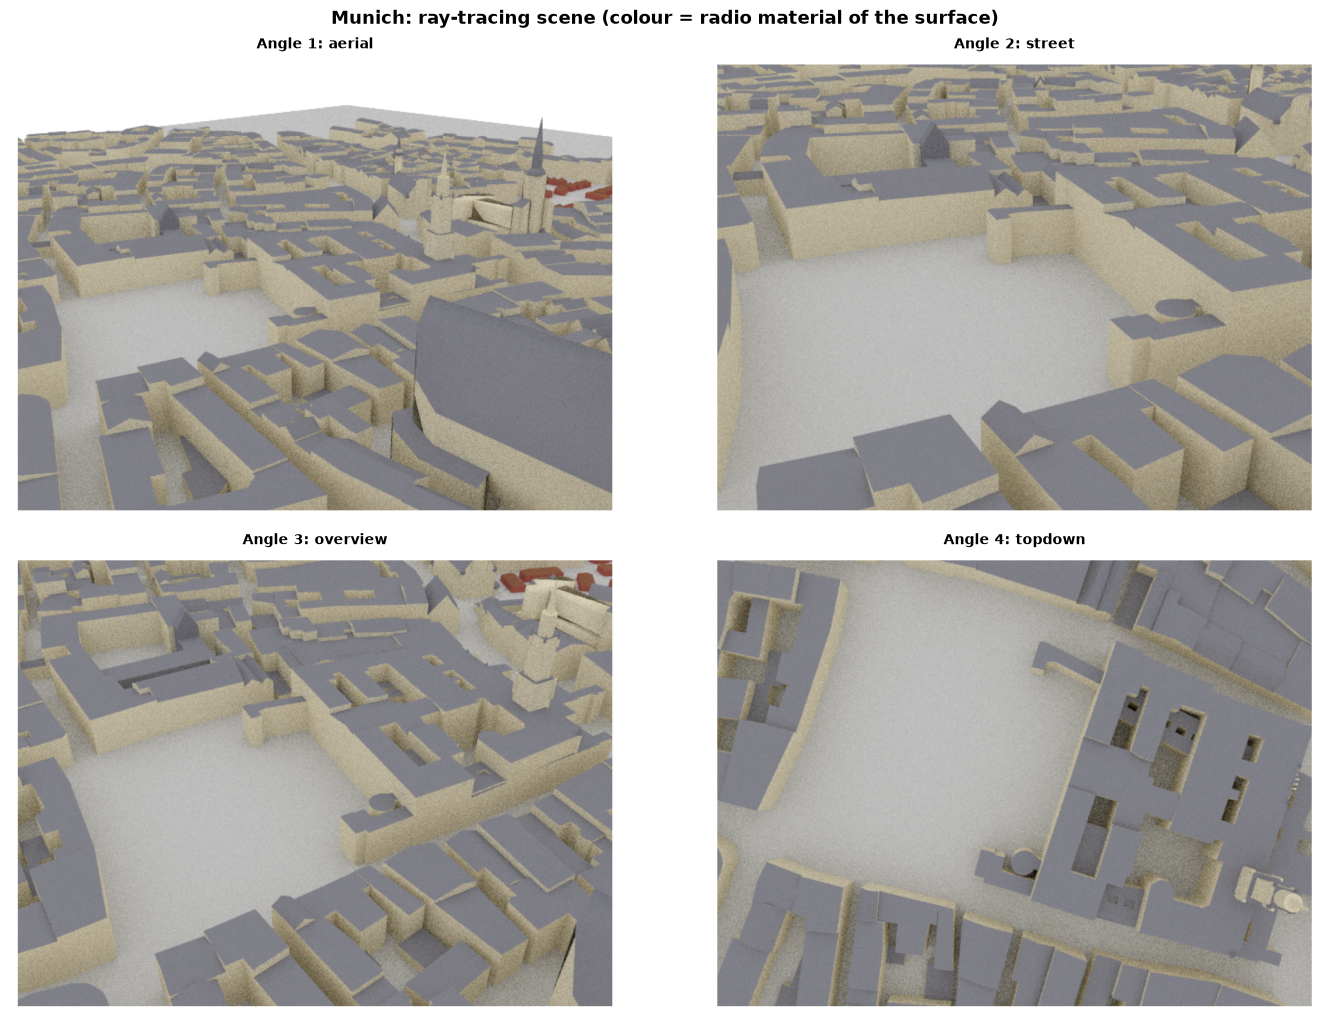

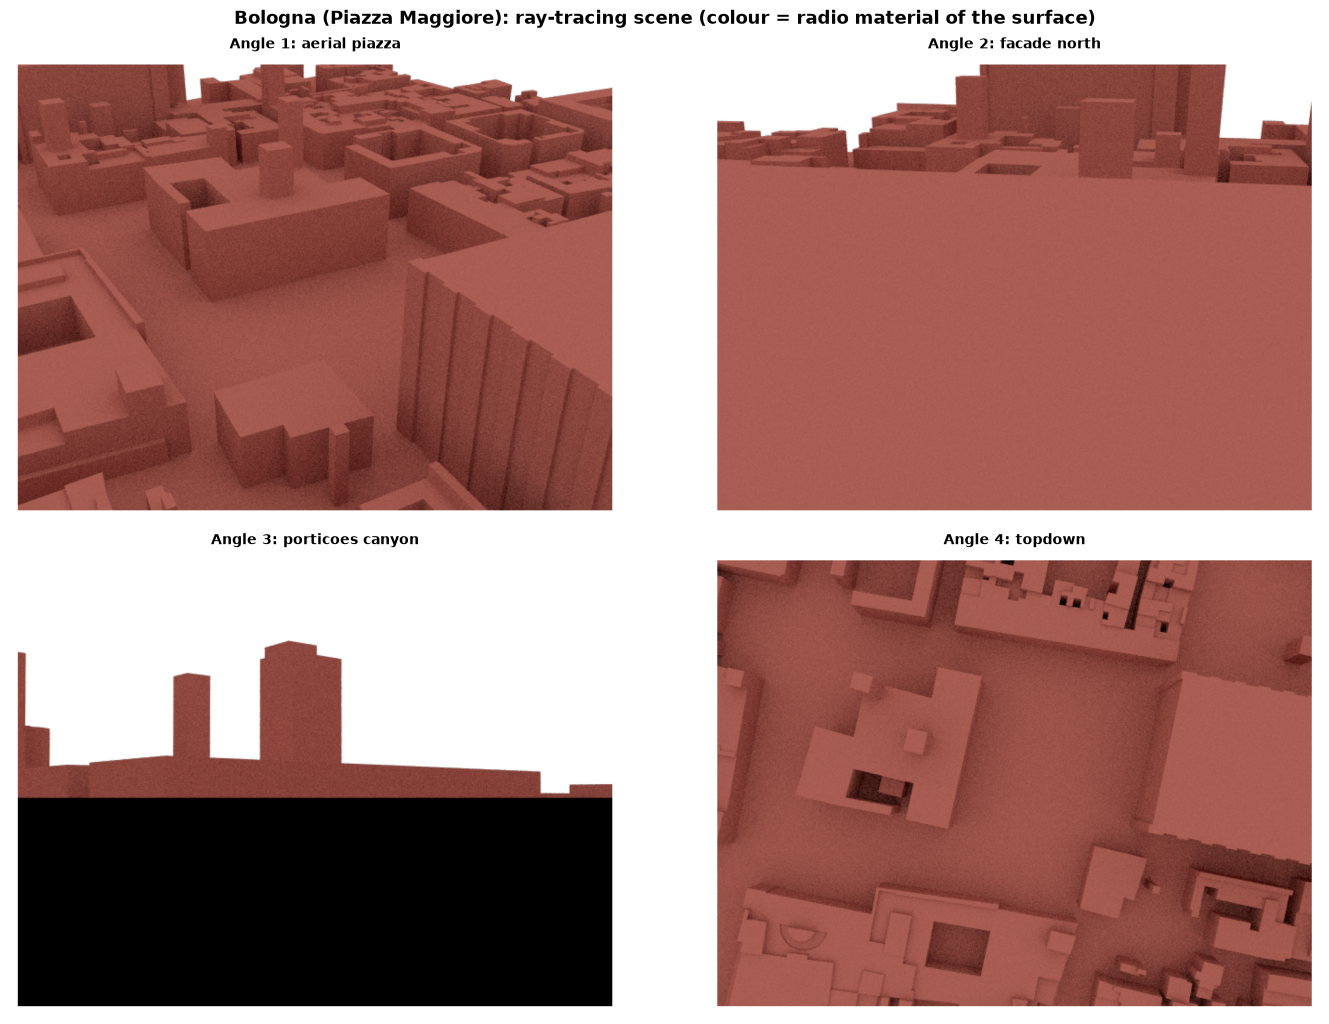

In [32]:
def is_black_frame(img: np.ndarray, lum_thr: float = 0.08, frac: float = 0.6) -> bool:
    """True when most pixels are almost black (camera inside geometry, failed render...)."""
    rgb = img[..., :3].astype(np.float32)
    if rgb.max() > 1.5:
        rgb = rgb / 255.0
    return float((rgb.mean(axis=-1) < lum_thr).mean()) > frac


# Camera views (position, look-at point, in metres). The file name encodes the angle number and a label.
RENDER_VIEWS = {
    "munich": [
        {"name": "angle1_aerial",   "pos": [-250.0, 250.0, 150.0], "look_at": [-15.0, 30.0, 28.0]},
        {"name": "angle2_street",   "pos": [-120.0, 170.0, 100.0], "look_at": [30.0, 55.0, 12.0]},
        {"name": "angle3_overview", "pos": [-150.0, 210.0, 200.0], "look_at": [20.0, 40.0, 10.0]},
        {"name": "angle4_topdown",  "pos": [20.0, 40.0, 320.0],    "look_at": [20.0, 40.0, 0.0]},
    ],
    "bologna": [
        {"name": "angle1_aerial_piazza",    "pos": [-120.0, -140.0, 110.0], "look_at": [0.0, 0.0, 10.0]},
        {"name": "angle2_facade_north",     "pos": [0.0, -90.0, 35.0],      "look_at": [0.0, 20.0, 12.0]},
        {"name": "angle3_porticoes_canyon", "pos": [-65.0, -25.0, 5.0],     "look_at": [15.0, 35.0, 22.0]},
        {"name": "angle4_topdown",          "pos": [0.0, 0.0, 320.0],       "look_at": [0.0, 0.0, 0.0]},
    ],
}


def render_scene_views(cfg: ProjectConfig, views: List[dict], out_dir: Path, max_retries: int = 4, lift_m: float = 15.0) -> List[Path]:
    """Render camera views with Sionna RT. A black frame (camera inside geometry) is retried with a higher camera."""
    scene = load_scene(str(cfg.scene_xml_path))
    out_dir.mkdir(parents=True, exist_ok=True)
    kept = []
    for v in views:
        pos = list(v["pos"])
        path = out_dir / f"{cfg.scene_name}_rtx_{v['name']}.png"
        tmp = out_dir / f"_tmp_{path.name}"                  # a failed render never replaces an existing good file
        for attempt in range(max_retries + 1):
            fig = scene.render(camera=Camera(position=pos, look_at=v["look_at"]), resolution=[640, 480], num_samples=32)
            fig.savefig(tmp, dpi=130, bbox_inches="tight")
            plt.close(fig)
            if not is_black_frame(plt.imread(tmp)):
                save_with_backup(path, lambda p: shutil.copy2(tmp, p))
                kept.append(path)
                break
            print(f"  [{cfg.scene_name}] {v['name']}: black frame at z = {pos[2]:.0f} m, raising the camera by {lift_m:.0f} m")
            pos[2] += lift_m
        else:
            print(f"  [{cfg.scene_name}] {v['name']}: still black after {max_retries} retries, view dropped")
        tmp.unlink(missing_ok=True)
    return kept


def collect_scene_renders(cfg: ProjectConfig) -> List[Tuple[str, np.ndarray]]:
    """One valid (non-black) render per camera angle, read from results/."""
    views: Dict[int, Tuple[str, np.ndarray]] = {}
    pattern = re.compile(rf"{cfg.scene_name}_rtx_angle(\d+)_?(.*)\.png")
    for folder in (cfg.results_dir,):
        files = sorted(folder.glob(f"{cfg.scene_name}_rtx_angle*.png"), key=lambda p: -len(p.name))
        for f in files:                                     # most descriptive file names first
            m = pattern.fullmatch(f.name)
            if not m or int(m.group(1)) in views:
                continue
            angle, label = int(m.group(1)), m.group(2).replace("_", " ") or "view"
            img = plt.imread(f)
            if is_black_frame(img):
                print(f"  skipped black frame: {f}")
            else:
                views[angle] = (f"Angle {angle}: {label}", img)
    return [views[a] for a in sorted(views)]


def show_scene_renders(cfg: ProjectConfig) -> None:
    views = collect_scene_renders(cfg)
    if not views:
        print(f"No valid render found for {cfg.display_name}")
        return
    ncols = min(len(views), 2)
    nrows = int(np.ceil(len(views) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2 * ncols, 5.2 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, img) in zip(axes.flat, views):
        ax.imshow(img)
        ax.set_title(title, fontsize=10, fontweight="bold")
    fig.suptitle(f"{cfg.display_name}: ray-tracing scene (colour = radio material of the surface)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


if RUN["renders"]:
    if SIONNA_OK:
        for scene in RENDER_SCENES:
            render_scene_views(CFG[scene], RENDER_VIEWS[scene], CFG[scene].results_dir)
    else:
        print("Sionna RT is not installed: showing the archived renders only.")

for scene in SCENES:
    show_scene_renders(CFG[scene])

**Reading the renders.** Munich is an open, orthogonal grid with large squares, while the Bologna model has dense blocks and narrow canyons, so signals bounce more. Both scenes are *approximate digital twins*: Bologna's heights are estimated from OSM tags or default values and its materials are generic (limitation 1, section 15). What matters for the project is that the two cities give **different, realistic multipath statistics** to test the same compression pipeline (section 13).

## **5 · From ray tracing to a CSI dataset**

One dataset = 5,000 UE positions → 5,000 channels **H** ∈ ℂ^{8×8}. Pipeline:

1. **Scene + radio** (`build_scene`): load the scene, set 3.5 GHz / 20 MHz, attach the two 1×8 arrays, put the gNB on the roof.
2. **Radio map** (`compute_radio_map`): path gain on a 2 m grid. It tells *where a UE can exist*: we keep outdoor cells that are 10–220 m from the gNB with path gain ≥ −135 dB.
3. **UE sampling** (`sample_ue_positions`): 5,000 (+12 % spare) cells drawn **without replacement**, with a sub-cell random jitter. Without this, two UEs in the same cell would be near-duplicates and leak between train and test.
4. **Path solver** (`trace_channels`): for each UE, Sionna finds the paths $k$ (line of sight, specular reflections, refractions, diffraction, up to 5 interactions), each with complex gain $a_k$ and delay $\tau_k$. The antenna arrays are applied analytically (`synthetic_array=True`), and the narrow-band channel at the carrier is
$$H[r,t]=\sum_k a_k[r,t]\,e^{-j2\pi f\tau_k},\qquad f=0\ \text{(carrier)}.$$
5. **Normalisation** (`normalize_channels`): every channel is rescaled to $\lVert H\rVert_F=8$ (unit average power per coefficient). Raw channels span **~118 dB** of path loss, which would let the closest UEs dominate the loss and destabilise training. The same operation is done in practice by feeding back the *shape* of H and a separate scalar gain.
6. **Two views of the same data**: `X_spatial` (Re/Im of H, shape 2×8×8, the network input) and `X_angular` (unitary 2D-DFT of H, used only for the domain study of section 14).

In [33]:
def build_scene(cfg: ProjectConfig):
    """Load the urban scene, set the radio parameters, attach the 8-element ULAs and the gNB."""
    xml_path = cfg.scene_xml_path
    if not xml_path.exists():
        raise FileNotFoundError(f"Scene XML not found: {xml_path} (Bologna: see Appendix A)")
    scene = load_scene(str(xml_path))
    scene.frequency = cfg.carrier_freq_hz
    scene.bandwidth = cfg.bandwidth_hz
    # 1x8 uniform linear arrays, half-wavelength spacing -> 8x8 MIMO
    scene.tx_array = PlanarArray(num_rows=1, num_cols=cfg.num_tx_ant, vertical_spacing=0.5,
                                 horizontal_spacing=0.5, pattern="tr38901", polarization="V")
    scene.rx_array = PlanarArray(num_rows=1, num_cols=cfg.num_rx_ant, vertical_spacing=0.5,
                                 horizontal_spacing=0.5, pattern="dipole", polarization="V")
    scene.add(Transmitter(name="tx", position=list(cfg.tx_position), look_at=list(cfg.tx_look_at),
                          power_dbm=cfg.tx_power_dbm, display_radius=2.5))
    return scene


def compute_radio_map(scene, cfg: ProjectConfig):
    """Path-gain map of the area on a regular grid (Monte-Carlo ray shooting)."""
    return RadioMapSolver()(scene=scene, max_depth=5, samples_per_tx=10**6, refraction=True,
                            center=list(cfg.rm_center), size=list(cfg.rm_size),
                            orientation=[0.0, 0.0, 0.0], cell_size=list(cfg.rm_cell_size))


def sample_ue_positions(rm, cfg: ProjectConfig, rng: np.random.Generator):
    """Draw candidate UE positions (unique cells + sub-cell jitter) among valid outdoor cells."""
    pg = rm.path_gain.numpy()[0]
    centers = rm.cell_centers.numpy()
    dist = np.linalg.norm(centers - np.array(cfg.tx_position, dtype=np.float32), axis=-1)
    with np.errstate(divide="ignore"):
        pg_db = 10.0 * np.log10(pg)
    valid = (np.isfinite(pg_db) & (pg_db >= cfg.min_path_gain_db)
             & (dist >= cfg.min_tx_dist_m) & (dist <= cfg.max_tx_dist_m))
    valid_centers, valid_pg_db = centers[valid], pg_db[valid]
    print(f"  valid outdoor cells: {len(valid_centers)} / {pg.size}")

    n_cand = min(len(valid_centers), int(cfg.num_realizations * 1.12))
    chosen = rng.choice(len(valid_centers), size=n_cand, replace=False)     # no cell twice
    pos = valid_centers[chosen].copy()
    pos[:, 0] += rng.uniform(-0.5 * cfg.rm_cell_size[0], 0.5 * cfg.rm_cell_size[0], size=n_cand)
    pos[:, 1] += rng.uniform(-0.5 * cfg.rm_cell_size[1], 0.5 * cfg.rm_cell_size[1], size=n_cand)
    return pos, valid_pg_db[chosen]


def trace_channels(scene, positions: np.ndarray, cfg: ProjectConfig):
    """Run the PathSolver by batches of receivers; return complex H [N, 8, 8] and the valid-path count per UE."""
    solver = PathSolver()
    H_parts, n_paths_parts = [], []
    for start in range(0, len(positions), cfg.rt_batch_size):
        for name in list(scene.receivers.keys()):
            scene.remove(name)
        for k, xyz in enumerate(positions[start:start + cfg.rt_batch_size]):
            scene.add(Receiver(name=f"rx_{k}", position=xyz.tolist()))
        paths = solver(scene=scene, max_depth=5, samples_per_src=2 * 10**5, los=True,
                       specular_reflection=True, diffuse_reflection=False, refraction=True,
                       diffraction=True, synthetic_array=True, seed=41 + start)
        # cfr: (rx, rx_ant, tx, tx_ant, time, freq) -> keep tx 0, first time step, carrier frequency
        cfr = paths.cfr(frequencies=np.array([0.0]), normalize_delays=False, out_type="numpy")
        H_parts.append(cfr[:, :, 0, :, 0, 0])
        n_paths_parts.append(paths.valid.numpy()[:, 0, :].sum(axis=1))
    return np.concatenate(H_parts), np.concatenate(n_paths_parts)


def normalize_channels(H_all, n_paths_all, positions, rm_pg_db, cfg: ProjectConfig) -> Dict[str, np.ndarray]:
    """Drop empty channels, normalise to ||H||_F = 8 and build the spatial (Re/Im) and angular (2D-DFT) views."""
    norms = np.linalg.norm(H_all, axis=(1, 2))
    keep = np.where(norms > 1e-12)[0][: cfg.num_realizations]
    if len(keep) < cfg.num_realizations:
        raise RuntimeError(f"Only {len(keep)} valid channels found; increase the number of candidates.")
    H_raw = H_all[keep].astype(np.complex64)
    frob = norms[keep].astype(np.float32)
    scale = np.sqrt(cfg.num_rx_ant * cfg.num_tx_ant) / frob[:, None, None]        # -> ||H||_F = 8
    H_norm = (H_raw * scale).astype(np.complex64)
    H_ang = np.fft.fftshift(np.fft.fft2(H_norm, norm="ortho"), axes=(1, 2))      # unitary 2D-DFT
    return {
        "H_raw": H_raw, "H_norm": H_norm,
        "X_spatial": np.stack([H_norm.real, H_norm.imag], axis=1).astype(np.float32),
        "X_angular": np.stack([H_ang.real, H_ang.imag], axis=1).astype(np.float32),
        "rx_positions": positions[keep].astype(np.float32),
        "num_paths": n_paths_all[keep].astype(np.int32),
        "frob_norms": frob,
        "rm_path_gain_db": rm_pg_db[keep].astype(np.float32),
    }


def generate_or_load_csi_dataset(cfg: ProjectConfig, regenerate: bool = False) -> Dict[str, np.ndarray]:
    """Load the archived CSI cache; or (regenerate=True / no cache) run the full Sionna RT pipeline."""
    if cfg.dataset_cache.exists() and not regenerate:
        data = dict(np.load(cfg.dataset_cache))
        print(f"[{cfg.scene_name}] loaded {cfg.dataset_cache}: {len(data['X_spatial'])} channels of shape {data['X_spatial'].shape[1:]}")
        return data
    if not SIONNA_OK:
        raise RuntimeError("Sionna RT is not installed, ray tracing is impossible here")
    t0 = time.time()
    print(f"[{cfg.scene_name}] ray tracing ...")
    scene = build_scene(cfg)
    rm = compute_radio_map(scene, cfg)
    rng = np.random.default_rng(cfg.seed)
    positions, rm_pg_db = sample_ue_positions(rm, cfg, rng)
    H_all, n_paths = trace_channels(scene, positions, cfg)
    data = normalize_channels(H_all, n_paths, positions, rm_pg_db, cfg)
    # never overwrite the archived cache: a re-generated dataset goes to results/live/
    out = cfg.dataset_cache if not cfg.dataset_cache.exists() else cfg.live_dir / cfg.dataset_cache.name
    out.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out, **data)
    print(f"[{cfg.scene_name}] saved in {time.time() - t0:.0f} s -> {out}")
    return data

**Load the data.** Without ray tracing this reads the archived caches (`data/*_csi_5000.npz`) in about a second. With `RUN["ray_tracing"] = True` (section 2) Sionna RT is re-run for the chosen cities (if it fails, the archived cache is used).
Then the **train / validation / test split**: a seeded random permutation of the 5,000 channels (3,500 / 750 / 750). The test set is never used to choose anything: the validation set picks the best checkpoint, and test KPIs are reported once.

In [34]:
def make_splits(n: int, cfg: ProjectConfig) -> Dict[str, np.ndarray]:
    """Deterministic 70/15/15 split of the sample indices."""
    perm = np.random.default_rng(cfg.seed).permutation(n)
    n_tr, n_va = int(cfg.train_ratio * n), int(cfg.val_ratio * n)
    return {"train": perm[:n_tr], "val": perm[n_tr:n_tr + n_va], "test": perm[n_tr + n_va:]}


DATA, SPLITS = {}, {}
for scene in SCENES:
    want_rt = RUN["ray_tracing"] and scene in RAY_TRACE_SCENES
    for regenerate in ([True, False] if want_rt else [False]):      # ray tracing first, archived cache as fallback
        try:
            DATA[scene] = generate_or_load_csi_dataset(CFG[scene], regenerate=regenerate)
            SPLITS[scene] = make_splits(len(DATA[scene]["X_spatial"]), CFG[scene])
            break
        except Exception as err:
            print(f"[{scene}] {'ray tracing' if regenerate else 'loading'} failed: {err}")
    else:
        print(f"[{scene}] dataset unavailable -> its sections will be skipped")

rows = []
for scene, d in DATA.items():
    gain_db = 20 * np.log10(d["frob_norms"] / 8.0)
    rows.append({
        "city": CFG[scene].display_name, "channels": len(d["X_spatial"]),
        "train/val/test": "/".join(str(len(v)) for v in SPLITS[scene].values()),
        "median #paths": int(np.median(d["num_paths"])),
        "#paths p10-p90": f"{np.percentile(d['num_paths'], 10):.0f}-{np.percentile(d['num_paths'], 90):.0f}",
        "raw dynamic range [dB]": round(float(gain_db.max() - gain_db.min()), 1),
        "mean ||H||_F after norm.": round(float(np.linalg.norm(d["H_norm"], axis=(1, 2)).mean()), 4),
    })
display(pd.DataFrame(rows).set_index("city"))

[munich] loaded data/munich_csi_5000.npz: 5000 channels of shape (2, 8, 8)
[bologna] loaded data/bologna_csi_5000.npz: 5000 channels of shape (2, 8, 8)


,channels,train/val/test,median #paths,#paths p10-p90,raw dynamic range [dB],mean ||H||_F after norm.
city,,,,,,
Munich,5000,3500/750/750,21,4-100,118.2,8.0
Bologna (Piazza Maggiore),5000,3500/750/750,36,6-76,141.5,8.0


**Reading the table.** Every channel has exactly $\lVert H\rVert_F=8$ after normalisation (check column), while the raw channels differ by more than 100 dB, which is why we normalise. Bologna has a higher median number of propagation paths (36 vs. 21), i.e. a richer multipath environment in the modelled area; the next section shows how this looks in the channel matrix.\
Also, the paths percentile difference is larger in Bologna than in Milan, which is consistent with the higher median number of paths.\
raw dynamic range : higher range means some high values paths, means that we need normalization.\
frobenius mean after norm : the normalization worked well.\
Archived overview of where the 5,000 UEs are (coloured by split), the coverage map and the multipath/gain statistics:

Munich


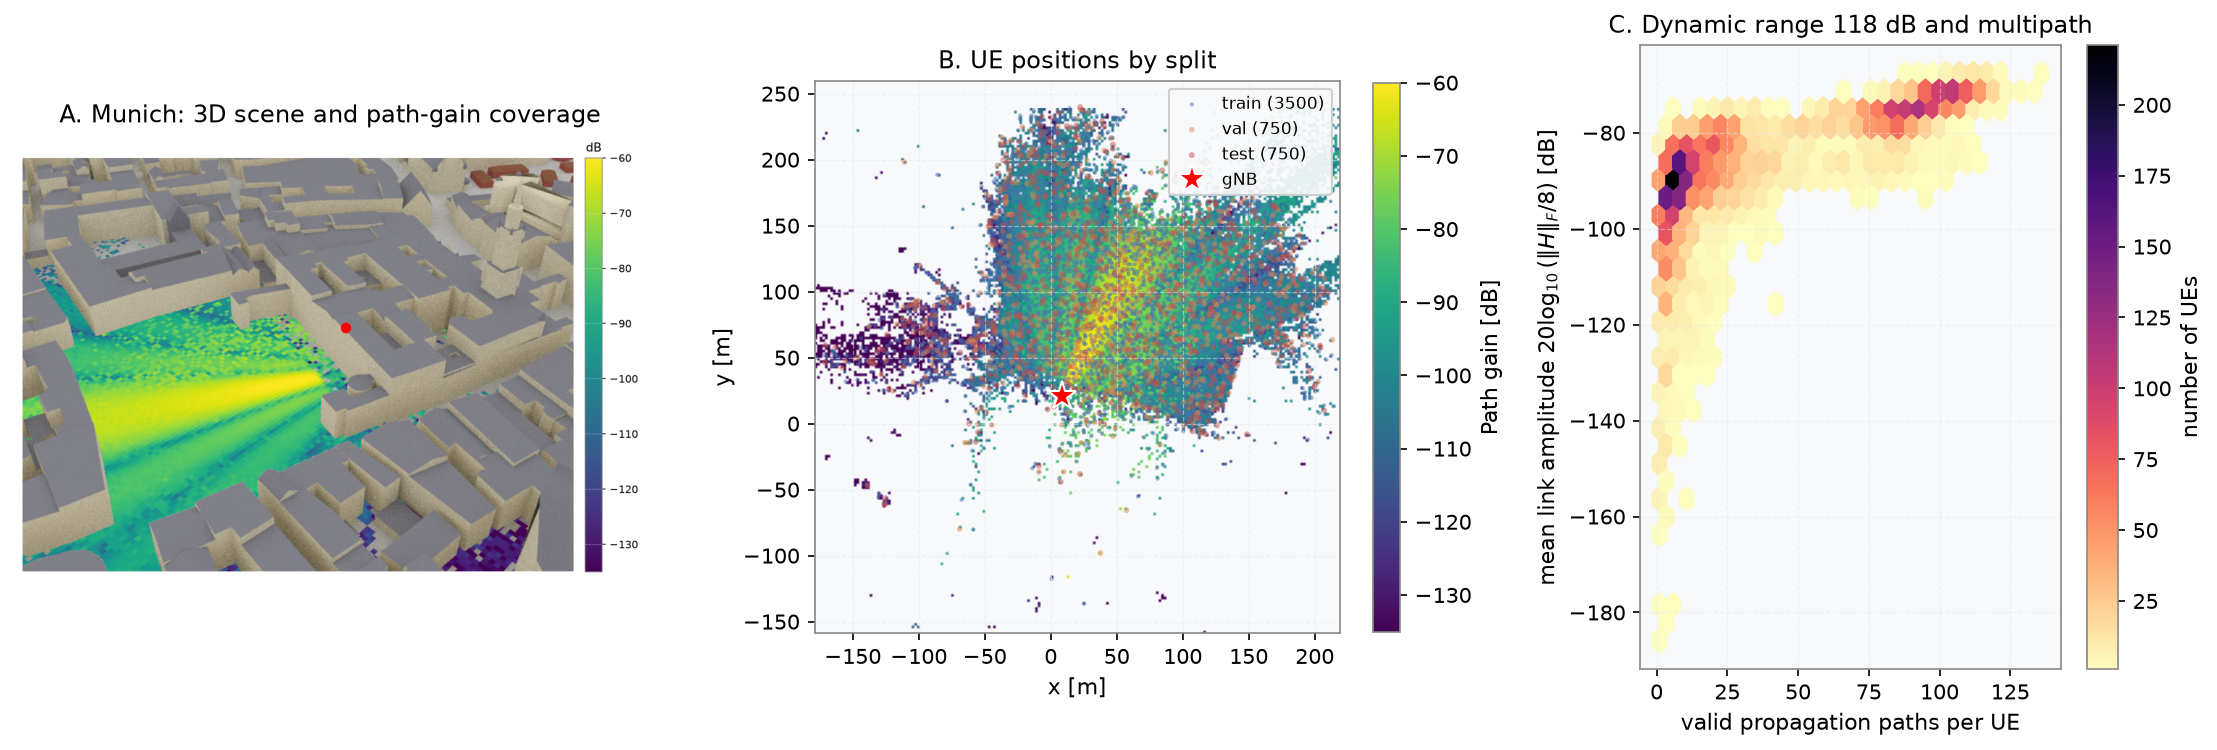

Bologna (Piazza Maggiore)


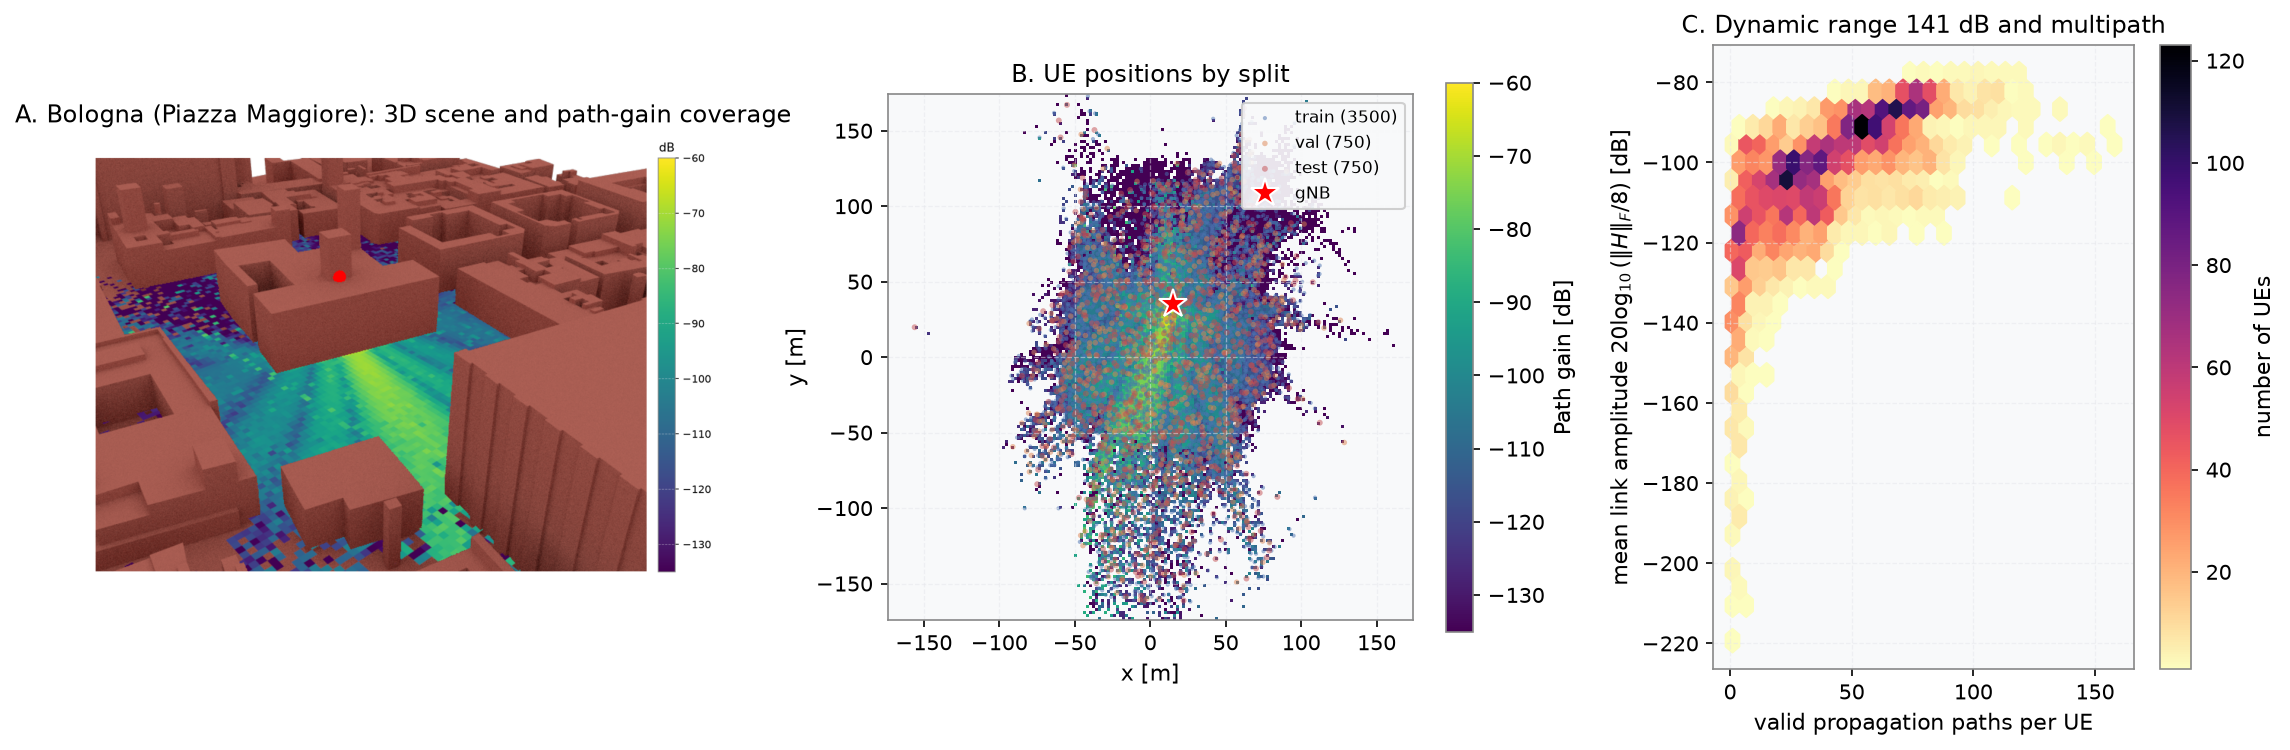

In [35]:
def fig_paths(cfg: ProjectConfig, name: str) -> Tuple[Path, Optional[Path]]:
    """(where a new figure is saved, existing cached file or None) for a per-scene figure."""
    return cfg.results_dir / f"{cfg.scene_name}_{name}", cfg.find_archived(name)


def show_archived(cfg: ProjectConfig, name: str, width: int = 1000) -> None:
    """Display a figure already stored in results/ (skips quietly if it is not there)."""
    _, found = fig_paths(cfg, name)
    if found is None:
        print(f"[{cfg.scene_name}] figure '{name}' not found in {cfg.results_dir}/")
    else:
        display(Image(filename=str(found), width=width))


def plot_dataset_overview(dataset, splits, cfg: ProjectConfig):
    """3D scene + coverage, UE map by split, and channel statistics (needs Sionna RT)."""
    scene = build_scene(cfg)
    rm = compute_radio_map(scene, cfg)
    fig = plt.figure(figsize=(18.5, 5.4))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1.25, 1.0], wspace=0.28)

    ax3d = fig.add_subplot(gs[0, 0])
    render = scene.render(camera=Camera(position=list(cfg.cam_position), look_at=list(cfg.cam_look_at)),
                          resolution=[720, 540], num_samples=48, radio_map=rm, rm_metric="path_gain",
                          rm_vmin=cfg.min_path_gain_db, rm_vmax=-60.0, rm_show_color_bar=True)
    tmp = cfg.results_dir / f"_tmp_3d_{cfg.scene_name}.png"
    render.savefig(tmp, dpi=150, bbox_inches="tight"); plt.close(render)
    ax3d.imshow(plt.imread(tmp)); ax3d.axis("off"); ax3d.set_title(f"A. {cfg.display_name}: 3D scene and path-gain coverage")
    tmp.unlink(missing_ok=True)

    ax = fig.add_subplot(gs[0, 1])
    with np.errstate(divide="ignore"):
        pg_db = 10.0 * np.log10(rm.path_gain.numpy()[0])
    c = rm.cell_centers.numpy()
    im = ax.imshow(pg_db, origin="lower", cmap="viridis", vmin=cfg.min_path_gain_db, vmax=-60.0,
                   extent=[c[..., 0].min(), c[..., 0].max(), c[..., 1].min(), c[..., 1].max()])
    fig.colorbar(im, ax=ax, label="Path gain [dB]", shrink=0.88)
    for key, col, sz in [("train", "#4C72B0", 4), ("val", "#DD8452", 7), ("test", "#C44E52", 8)]:
        p = dataset["rx_positions"][splits[key]]
        ax.scatter(p[:, 0], p[:, 1], s=sz, c=col, alpha=0.5, label=f"{key} ({len(p)})", edgecolors="none")
    ax.plot(cfg.tx_position[0], cfg.tx_position[1], "*", color="red", ms=14, mec="white", label="gNB")
    ax.set(title="B. UE positions by split", xlabel="x [m]", ylabel="y [m]"); ax.legend(fontsize=8, loc="upper right")

    ax = fig.add_subplot(gs[0, 2])
    raw_db = 20.0 * np.log10(dataset["frob_norms"] / 8.0)
    hb = ax.hexbin(dataset["num_paths"], raw_db, gridsize=28, cmap="magma_r", mincnt=1)
    fig.colorbar(hb, ax=ax, label="number of UEs")
    ax.set(title=f"C. Dynamic range {raw_db.max() - raw_db.min():.0f} dB and multipath", xlabel="valid propagation paths per UE",
           ylabel=r"mean link amplitude $20\log_{10}(\|H\|_F/8)$ [dB]")
    return fig


for scene in DATA:
    print(CFG[scene].display_name)
    target, found = fig_paths(CFG[scene], "01_sionna_scene_and_radiomap.png")
    cached_figure(lambda: plot_dataset_overview(DATA[scene], SPLITS[scene], CFG[scene]), target, found,
                  force=RUN["ray_tracing"] and scene in RAY_TRACE_SCENES, can_draw=SIONNA_OK, width=1300)

## **6 · What does a CSI matrix look like?**

Four views of the same normalised channel (live, from the data): magnitude $|H|$, real part, phase, and the **angular domain** $|H_{ang}|$ obtained with a unitary 2D-DFT (a change of basis from antenna index to *angle of departure/arrival*).

We compare a UE with **few paths** (≈ 15th percentile) and one with **many paths** (≈ 90th percentile) from the test set.

Munich


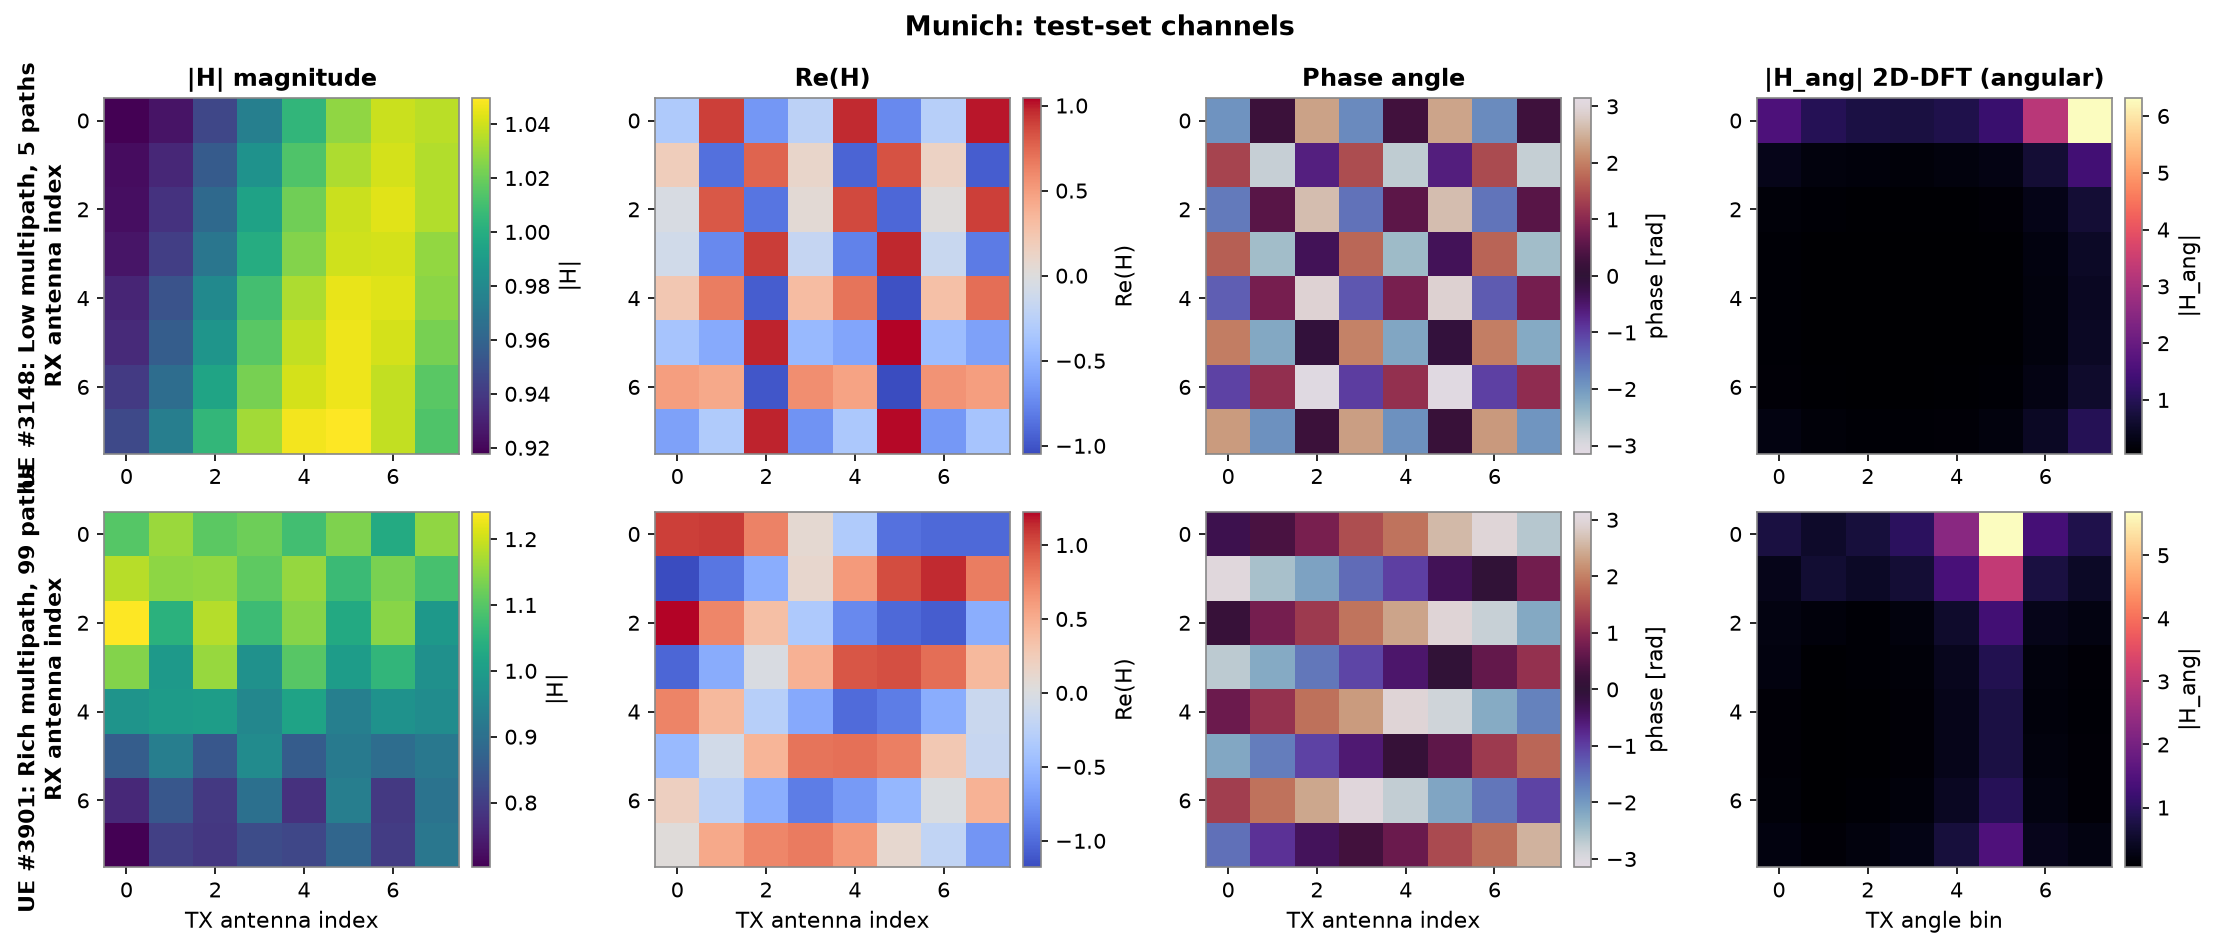

Bologna (Piazza Maggiore)


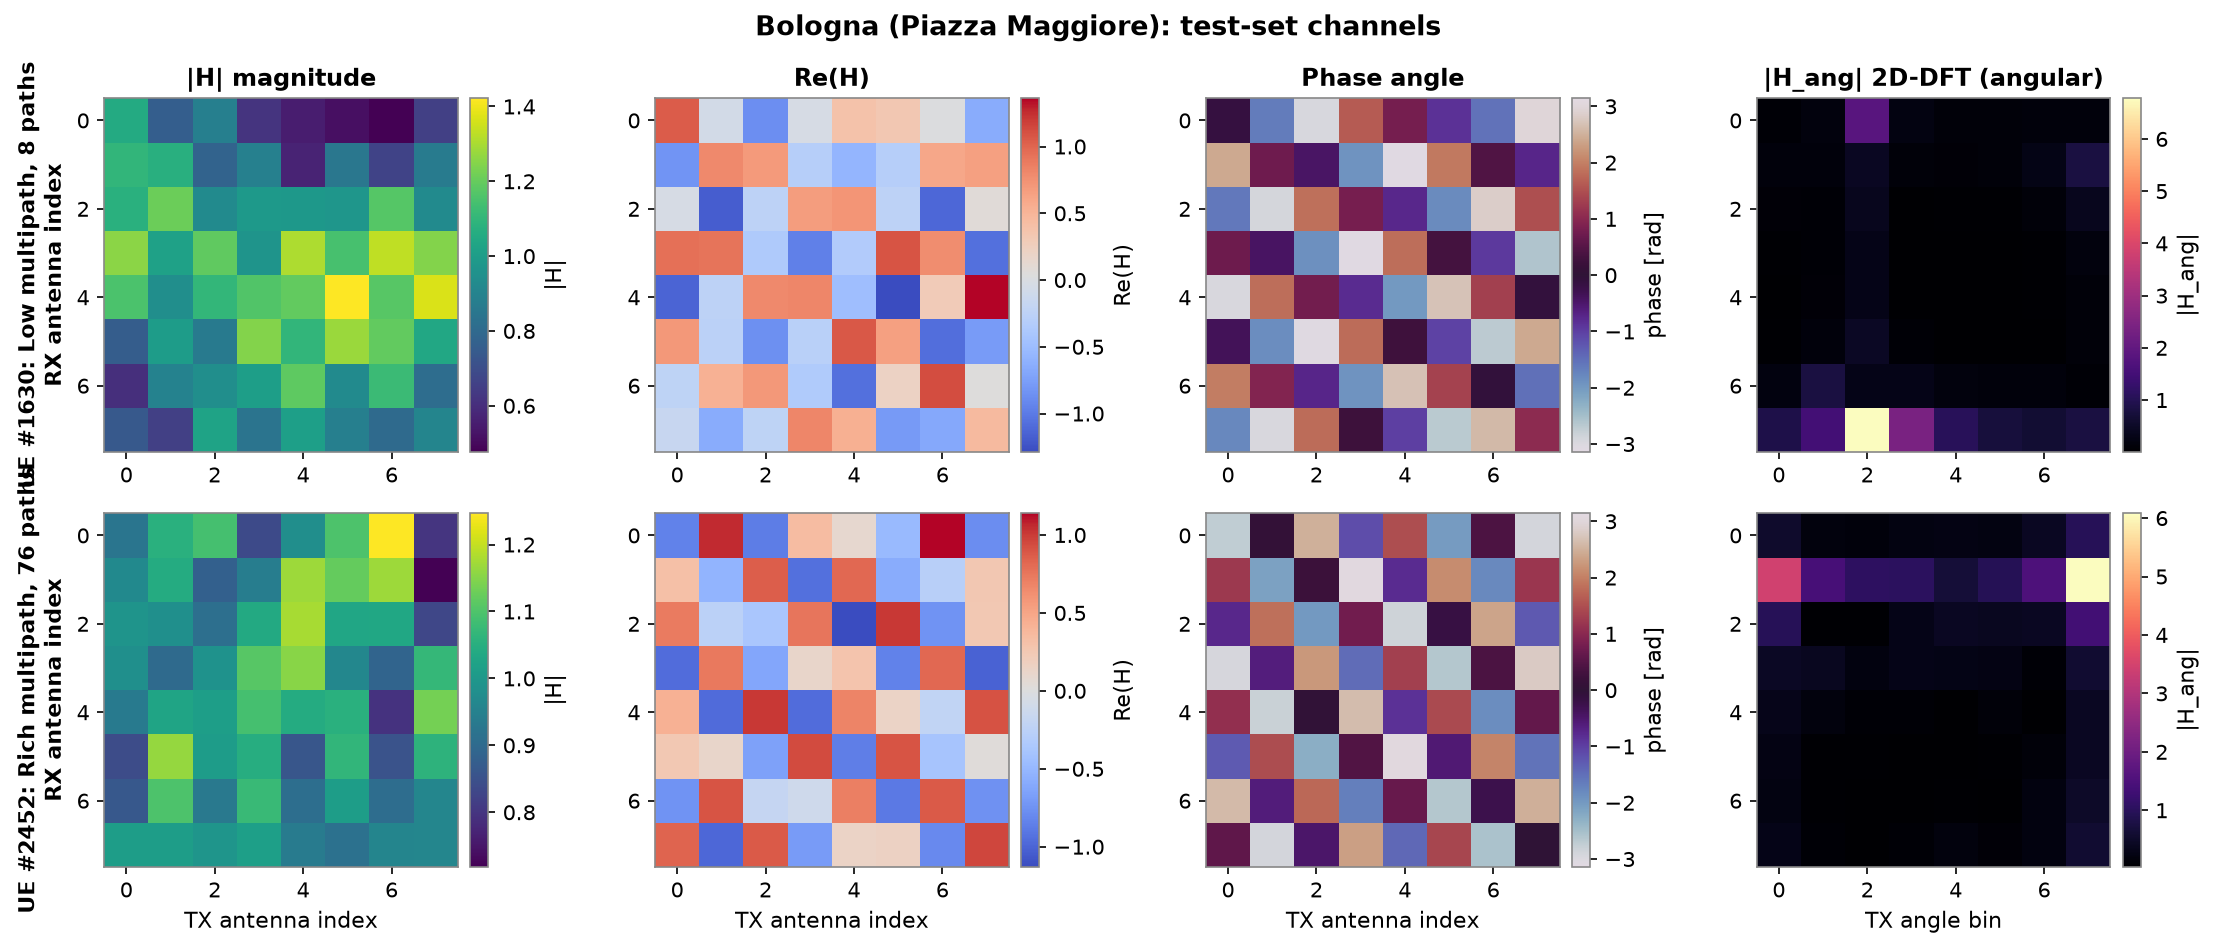

In [36]:
def plot_csi_domains(dataset: Dict[str, np.ndarray], splits: Dict[str, np.ndarray], title: str = ""):
    """Magnitude / real part / phase / angular-domain magnitude of a low- and a high-multipath test channel."""
    H_norm, paths = dataset["H_norm"], dataset["num_paths"]
    order = np.argsort(paths[splits["test"]])
    picks = [(splits["test"][order[int(0.15 * len(order))]], "Low multipath"),
             (splits["test"][order[int(0.90 * len(order))]], "Rich multipath")]
    titles = ["|H| magnitude", "Re(H)", "Phase angle", "|H_ang| 2D-DFT (angular)"]
    cbar_labels = ["|H|", "Re(H)", "phase [rad]", "|H_ang|"]
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
    for row, (idx, label) in enumerate(picks):
        H = H_norm[idx]
        H_ang = np.fft.fftshift(np.fft.fft2(H, norm="ortho"))
        for col, (img, cmap, kw) in enumerate([(np.abs(H), "viridis", {}), (H.real, "coolwarm", {}),
                                                (np.angle(H), "twilight", dict(vmin=-np.pi, vmax=np.pi)),
                                                (np.abs(H_ang), "magma", {})]):
            ax = axes[row, col]
            im = ax.imshow(img, cmap=cmap, **kw)
            ax.grid(False)
            ax.set_xticks(range(0, 8, 2)); ax.set_yticks(range(0, 8, 2))
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label=cbar_labels[col])
            if row == 0:
                ax.set_title(titles[col], fontweight="bold")
            if row == 1:
                ax.set_xlabel("TX antenna index" if col < 3 else "TX angle bin")
        axes[row, 0].set_ylabel(f"UE #{idx}: {label}, {paths[idx]} paths\nRX antenna index" if row == 0 else
                                f"UE #{idx}: {label}, {paths[idx]} paths\nRX antenna index", fontweight="bold")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    return fig


for scene in DATA:
    print(CFG[scene].display_name)
    target, found = fig_paths(CFG[scene], "02_csi_domain_inspection.png")
    cached_figure(lambda: plot_csi_domains(DATA[scene], SPLITS[scene], f"{CFG[scene].display_name}: test-set channels"),
                  target, found, force=RUN["ray_tracing"] and scene in RAY_TRACE_SCENES)

**Reading the figures.**
- *Few paths* (top): the magnitude varies smoothly across the array and the angular view is **sparse** (one or two bright pixels): a handful of paths = a handful of angles. This is the structure a compressor can exploit.
- *Many paths* (bottom): magnitude looks like a random pattern and the energy spreads over many angular bins: much less redundancy, so a harder channel to compress.
- Phase maps look "checkerboard-like" because the antennas are λ/2 apart, so a path adds a **linear phase ramp** along each array.

The angular view is the same information as the spatial one (a unitary transform preserves norms), but sparser for simple channels. We test later whether feeding it to the network helps (section 14).

## **7 · The autoencoders**

Both networks have the same interface: input $H\in\mathbb R^{2\times8\times8}$ → latent $z\in\mathbb R^{d}$ (the **only** thing the UE transmits) → output $\hat H\in\mathbb R^{2\times8\times8}$. The output layer is **linear** because channel coefficients are not bounded in a fixed range.

| | **Dense MLP** | **Residual 2D-CNN** (CsiNet-style) |
|---|---|---|
| Idea | flatten H to 128 numbers, fully connected layers | treat H as a 2-channel **image** of the antenna grid |
| Prior | none: every input can interact with every other | **locality + weight sharing**: neighbouring antennas have correlated channels |
| Encoder | 128 → 256 → 128 → $d$ | 3×3 convs (2→16→32), 1 residual block, conv (→16), flatten, linear → $d$ |
| Decoder | $d$ → 128 → 256 → 128 | linear → 16×8×8, conv (→32), 2 residual blocks, conv (→16), conv (→2) |
| Details | BatchNorm + LeakyReLU(0.2) | BatchNorm + LeakyReLU(0.2), **no stride/pooling** (the grid is only 8×8, down-sampling would destroy information) |

A **residual block** computes $x\mapsto \text{act}(x+F(x))$: the skip connection lets the block learn a *correction* and eases optimisation. **BatchNorm** normalises activations per mini-batch for stable, faster training.

In [37]:
class MLPAutoencoder(nn.Module):
    """Dense MLP CSI autoencoder: 2x8x8 -> flatten -> d -> 2x8x8."""

    def __init__(self, latent_dim: int, hidden_dim: int = 256) -> None:
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(hidden_dim, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(128, latent_dim),                              # linear bottleneck: z
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(128, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(hidden_dim, 128), nn.Unflatten(1, (2, 8, 8)),  # linear output
        )

    def encode(self, x): return self.encoder(x)
    def decode(self, z): return self.decoder(z)
    def forward(self, x): return self.decode(self.encode(x))


class ResidualConvBlock(nn.Module):
    """x -> act(x + conv-BN-act-conv-BN(x)): identity skip connection around two 3x3 convolutions."""

    def __init__(self, channels: int, bias: bool = True) -> None:
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=bias), nn.BatchNorm2d(channels), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1, bias=bias), nn.BatchNorm2d(channels),
        )
        self.act = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x): return self.act(x + self.conv(x))


class CNNAutoencoder(nn.Module):
    """Residual 2D-CNN CSI autoencoder that keeps the 8x8 antenna grid (no down-sampling)."""

    def __init__(self, latent_dim: int, conv_bias: bool = True) -> None:
        super().__init__()
        # conv_bias=True reproduces the architecture used for the archived results (141,810 params at d=32)
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(2, 16, 3, padding=1), nn.BatchNorm2d(16), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.LeakyReLU(0.2, inplace=True),
            ResidualConvBlock(32, conv_bias),
            nn.Conv2d(32, 16, 3, padding=1), nn.BatchNorm2d(16), nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(), nn.Linear(16 * 8 * 8, latent_dim),         # bottleneck: z
        )
        self.decoder_fc = nn.Sequential(nn.Linear(latent_dim, 16 * 8 * 8), nn.LeakyReLU(0.2, inplace=True),
                                        nn.Unflatten(1, (16, 8, 8)))
        self.decoder_conv = nn.Sequential(
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.LeakyReLU(0.2, inplace=True),
            ResidualConvBlock(32, conv_bias), ResidualConvBlock(32, conv_bias),
            nn.Conv2d(32, 16, 3, padding=1), nn.BatchNorm2d(16), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(16, 2, 3, padding=1),                          # linear output
        )

    def encode(self, x): return self.encoder_conv(x)
    def decode(self, z): return self.decoder_conv(self.decoder_fc(z))
    def forward(self, x): return self.decode(self.encode(x))


ARCHS = {"CNN": CNNAutoencoder, "MLP": MLPAutoencoder}


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Shapes through the network, and model sizes (the CNN is *smaller* than the MLP at high compression)
x = torch.zeros(4, 2, 8, 8)
for name, cls in ARCHS.items():
    m = cls(latent_dim=16).eval()
    print(f"{name}: input {tuple(x.shape)} -> z {tuple(m.encode(x).shape)} -> output {tuple(m(x).shape)}")
print()
for d in [32, 16, 8]:
    n_mlp, n_cnn = count_params(MLPAutoencoder(d)), count_params(CNNAutoencoder(d))
    print(f"CR {128 // d:2d}x (d={d:2d}) | MLP {n_mlp:>8,} params | CNN {n_cnn:>8,} params ({n_cnn - n_mlp:+,})")

CNN: input (4, 2, 8, 8) -> z (4, 16) -> output (4, 2, 8, 8)
MLP: input (4, 2, 8, 8) -> z (4, 16) -> output (4, 2, 8, 8)

CR  4x (d=32) | MLP  141,728 params | CNN  141,810 params (+82)
CR  8x (d=16) | MLP  137,616 params | CNN  109,026 params (-28,590)
CR 16x (d= 8) | MLP  135,560 params | CNN   92,634 params (-42,926)


In [38]:
# Block diagram of the split autoencoder (UE encoder / gNB decoder), if present in results/
for fig_name in ["diagram_split_autoencoder.png", "diagram_feedback_bottleneck.png"]:
    if (CFG["munich"].results_dir / fig_name).exists():
        display(Image(filename=str(CFG["munich"].results_dir / fig_name), width=900))

**Reading the model sizes.** The CNN has about as many parameters as the MLP at 4× but **~30 % fewer at 16×**, because its capacity sits in small shared 3×3 kernels, not in big dense matrices. So any CNN advantage is not a matter of "more parameters": it is the **inductive bias** of convolutions.
The MLP barely shrinks when $d$ decreases: the bottleneck layers are only a small part of its parameters.

## **8 · Loss and KPIs**

**Training loss** (exactly the project's $\mathcal L_{CSI}$): squared Frobenius norm of the error, averaged over the batch. Real and imaginary parts are stacked, so $\lVert H-\hat H\rVert_F^2$ is the sum of squares of all 128 differences.

**KPIs** (on the held-out test set, *normalised* channels):

| KPI | Definition | What it tells |
|---|---|---|
| **NMSE** (dB) | $10\log_{10}\dfrac{\sum_i\lVert H_i-\hat H_i\rVert_F^2}{\sum_i\lVert H_i\rVert_F^2}$ | reconstruction error relative to the signal energy. 0 dB = no better than sending zeros |
| **Median NMSE** | median over UEs of the per-UE NMSE (dB) | the *typical* UE (the aggregate is dominated by the worst ones) |
| **Cosine similarity** ρ | $\dfrac{\lvert\langle H,\hat H\rangle\rvert}{\lVert H\rVert\lVert\hat H\rVert}$ (complex inner product) | alignment of Ĥ with H, insensitive to a global scale: what beamforming cares about |
| **Dominant singular value retention** | $\sigma_{max}(\hat H)/\sigma_{max}(H)$ | is the strongest spatial mode (used by SVD beamforming) preserved? |
| **Compression ratio** | $D/d=128/d$ | ratio of *real dimensions*, not a bit-rate: the latent is not quantised |

In [39]:
def frobenius_mse_loss(x_true: torch.Tensor, x_hat: torch.Tensor) -> torch.Tensor:
    """L_CSI = mean over the batch of ||H - H_hat||_F^2 (inputs: [B, 2, 8, 8])."""
    return torch.mean(torch.sum((x_true - x_hat) ** 2, dim=(1, 2, 3)))


def compute_csi_metrics(X_true: np.ndarray, X_hat: np.ndarray) -> Dict[str, object]:
    """NMSE (aggregate / per UE), cosine similarity and dominant-singular-value retention. Inputs: [N, 2, 8, 8]."""
    err = np.sum((X_true - X_hat) ** 2, axis=(1, 2, 3))
    ref = np.sum(X_true ** 2, axis=(1, 2, 3))
    nmse_db_ue = 10.0 * np.log10(np.maximum(err / np.maximum(ref, 1e-12), 1e-12))

    Ht, Hh = X_true[:, 0] + 1j * X_true[:, 1], X_hat[:, 0] + 1j * X_hat[:, 1]     # back to complex matrices
    inner = np.abs(np.sum(np.conj(Ht) * Hh, axis=(1, 2)))
    rho = inner / np.maximum(np.linalg.norm(Ht, axis=(1, 2)) * np.linalg.norm(Hh, axis=(1, 2)), 1e-12)
    svd_ratio = np.linalg.svd(Hh, compute_uv=False)[:, 0] / np.maximum(np.linalg.svd(Ht, compute_uv=False)[:, 0], 1e-12)

    return {
        "aggregate_nmse_db": float(10.0 * np.log10(max(err.sum() / max(ref.sum(), 1e-12), 1e-12))),
        "median_nmse_db": float(np.median(nmse_db_ue)),
        "p10_nmse_db": float(np.percentile(nmse_db_ue, 10)),
        "p90_nmse_db": float(np.percentile(nmse_db_ue, 90)),
        "mean_rho": float(rho.mean()), "median_rho": float(np.median(rho)),
        "mean_svd_ratio": float(svd_ratio.mean()),
        "nmse_db_per_sample": nmse_db_ue, "rho_per_sample": rho,
    }

**Sanity checks of the KPI code** (live, on real channels), with results we can predict by hand:
1. add i.i.d. noise of std σ = 0.1 on the 128 values: error energy = 128σ² = 1.28 against a signal energy of 64 → NMSE = 10·log₁₀(0.02) = **−16.99 dB**;
2. output zeros: NMSE = **0 dB**, cosine similarity undefined (0);
3. output the exact input: NMSE hits the numerical floor (−120 dB), ρ = 1, SVD ratio = 1.

Also a reading aid: what a given NMSE means in *percentage of energy lost*.

In [40]:
X_ref = (DATA.get("munich") or next(iter(DATA.values())))["X_spatial"][:200]
rng_check = np.random.default_rng(0)
tests = {
    "noise sigma=0.1 (expected -16.99 dB)": X_ref + 0.1 * rng_check.standard_normal(X_ref.shape).astype(np.float32),
    "all zeros (expected 0 dB)": np.zeros_like(X_ref),
    "perfect copy (expected floor)": X_ref.copy(),
}
for label, X_hat in tests.items():
    k = compute_csi_metrics(X_ref, X_hat)
    print(f"{label:38s} NMSE {k['aggregate_nmse_db']:8.2f} dB | cos {k['mean_rho']:.3f} | SVD ratio {k['mean_svd_ratio']:.3f}")

print("\nNMSE [dB] -> share of the channel energy that is NOT recovered")
for db in [-3, -7, -10, -14, -20]:
    print(f"  {db:>4d} dB -> {100 * 10 ** (db / 10):5.1f} %")

noise sigma=0.1 (expected -16.99 dB)   NMSE   -17.03 dB | cos 0.990 | SVD ratio 1.003
all zeros (expected 0 dB)              NMSE     0.00 dB | cos 0.000 | SVD ratio 0.000
perfect copy (expected floor)          NMSE  -120.00 dB | cos 1.000 | SVD ratio 1.000

NMSE [dB] -> share of the channel energy that is NOT recovered
    -3 dB ->  50.1 %
    -7 dB ->  20.0 %
   -10 dB ->  10.0 %
   -14 dB ->   4.0 %
   -20 dB ->   1.0 %


**Reading the checks.** The three controlled cases give exactly the predicted values, so the KPI code is correct. The last table is the key to interpreting the results: −7 dB (our 16× CNN) means ~20 % of the channel energy is lost, −14 dB (our 4× CNN) only ~4 %.

## **9 · Training and the PCA baseline**

**Training recipe** (identical for MLP and CNN, every city and every $d$):
- **AdamW** (Adam with decoupled weight decay 1e-5), initial learning rate 2·10⁻³, avoids weight peaks and overfitting because the paths are highly concentrated;
- **cosine annealing** of the learning rate down to 10⁻⁵ over 120 epochs: large steps first, fine convergence at the end;
- mini-batches of 128; after each epoch the **validation** loss is computed and the **best-validation weights are restored** at the end (a cheap form of early stopping), 5000/128~39 iterations;
- the test set is evaluated once, with those best weights.

Validation NMSE is computed as $10\log_{10}(\text{loss}/64)$ because every channel has energy $\lVert H\rVert_F^2=64$.

**PCA baseline.** The best *linear* $d$-dimensional compressor: project the (mean-removed) 128-dim vectors on the $d$ leading principal directions, obtained by SVD of the training set (Eckart–Young theorem: no other rank-$d$ linear map does better in MSE). It needs no training and answers the question *"is a neural network actually worth it?"*: the gap between PCA and an autoencoder is the benefit of **non-linearity**.

In [41]:
def make_loaders(dataset: Dict[str, np.ndarray], splits: Dict[str, np.ndarray], cfg: ProjectConfig):
    """Tensors/loaders for the spatial (Re/Im) representation. Returns train/val loaders and the numpy test set."""
    X = dataset["X_spatial"]
    train = DataLoader(TensorDataset(torch.from_numpy(X[splits["train"]])), batch_size=cfg.batch_size, shuffle=True)
    val = DataLoader(TensorDataset(torch.from_numpy(X[splits["val"]])), batch_size=cfg.batch_size, shuffle=False)
    return train, val, X[splits["test"]], X[splits["train"]]


def train_and_evaluate_model(model, train_loader, val_loader, X_test, cfg: ProjectConfig, device):
    """Train with AdamW + cosine annealing, restore the best-validation weights, evaluate on the test set."""
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs, eta_min=cfg.min_lr)
    history = {"train_loss": [], "val_loss": [], "val_nmse_db": []}
    best_val, best_weights = float("inf"), None

    t0 = time.time()
    for _ in range(cfg.epochs):
        model.train()
        tr_sum, tr_n = 0.0, 0
        for (xb,) in train_loader:
            xb = xb.to(device)
            optimizer.zero_grad()
            loss = frobenius_mse_loss(xb, model(xb))
            loss.backward()
            optimizer.step()
            tr_sum += loss.item() * len(xb); tr_n += len(xb)
        scheduler.step()

        model.eval()
        va_sum, va_n = 0.0, 0
        with torch.no_grad():
            for (xb,) in val_loader:
                xb = xb.to(device)
                va_sum += frobenius_mse_loss(xb, model(xb)).item() * len(xb); va_n += len(xb)
        tr, va = tr_sum / tr_n, va_sum / va_n
        history["train_loss"].append(tr); history["val_loss"].append(va)
        history["val_nmse_db"].append(10.0 * np.log10(max(va / 64.0, 1e-12)))
        if va < best_val:                                              # keep the best checkpoint
            best_val = va
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    train_time = time.time() - t0

    model.load_state_dict(best_weights)
    model.eval()
    t1 = time.time()
    with torch.no_grad():
        X_hat = model(torch.from_numpy(X_test).to(device)).cpu().numpy()
    infer_ms = 1000 * (time.time() - t1) / len(X_test)
    return {"num_params": count_params(model), "train_time_sec": train_time, "infer_ms_per_ue": infer_ms,
            "best_val_loss": best_val, "history": history,
            "test_metrics": compute_csi_metrics(X_test, X_hat)}, X_hat


def evaluate_pca_baseline(X_train: np.ndarray, X_test: np.ndarray, latent_dim: int) -> Dict[str, object]:
    """Truncated-SVD (PCA) compression of the flattened 128-dim real vectors."""
    t0 = time.time()
    Xtr, Xte = X_train.reshape(len(X_train), -1), X_test.reshape(len(X_test), -1)
    mean = Xtr.mean(axis=0, keepdims=True)
    _, _, Vt = np.linalg.svd(Xtr - mean, full_matrices=False)
    V = Vt[:latent_dim].T                                             # [128, d] principal directions
    X_hat = ((Xte - mean) @ V @ V.T + mean).reshape(-1, 2, 8, 8)      # encode (project) then decode
    return {"num_params": 0, "train_time_sec": time.time() - t0, "infer_ms_per_ue": 0.0, "best_val_loss": float("nan"),
            "history": {"train_loss": [], "val_loss": [], "val_nmse_db": []},
            "test_metrics": compute_csi_metrics(X_test, X_hat), "X_hat": X_hat}


def run_experiment(cfg: ProjectConfig, dataset, splits, device, latent_dims=None, archs=("CNN", "MLP"), verbose=True):
    """Train every (architecture, d) pair + the PCA baseline. Returns (results[arch][d], reconstructions[arch][d], X_test)."""
    latent_dims = latent_dims or cfg.latent_dims
    train_loader, val_loader, X_test, X_train = make_loaders(dataset, splits, cfg)
    results = {a: {} for a in (*archs, "PCA")}
    recon = {a: {} for a in archs}
    for d in latent_dims:
        results["PCA"][d] = evaluate_pca_baseline(X_train, X_test, d)
        if verbose:
            print(f"d={d:2d} ({128 // d}x) PCA  : {results['PCA'][d]['test_metrics']['aggregate_nmse_db']:6.2f} dB")
        for a in archs:
            torch.manual_seed(cfg.seed)
            results[a][d], recon[a][d] = train_and_evaluate_model(ARCHS[a](d), train_loader, val_loader, X_test, cfg, device)
            if verbose:
                m = results[a][d]["test_metrics"]
                print(f"d={d:2d} ({128 // d}x) {a:4s} : {m['aggregate_nmse_db']:6.2f} dB | cos {m['mean_rho']:.4f} | {results[a][d]['train_time_sec']:.0f} s")
    return results, recon, X_test

**PCA baseline, live.** It needs no training, so we compute it right now on the real data of both cities (test NMSE for each compression ratio). These numbers are later compared with the archived ones as a **reproducibility check**: same seed → same split → same result.

In [42]:
PCA_LIVE = {}
for scene in DATA:
    _, _, X_test, X_train = make_loaders(DATA[scene], SPLITS[scene], CFG[scene])
    PCA_LIVE[scene] = {d: evaluate_pca_baseline(X_train, X_test, d)["test_metrics"] for d in CFG[scene].latent_dims}
    line = " | ".join(f"{128 // d:2d}x: {m['aggregate_nmse_db']:6.2f} dB" for d, m in PCA_LIVE[scene].items())
    print(f"{CFG[scene].display_name:26s} PCA  {line}")

Munich                     PCA   4x:  -7.07 dB |  8x:  -3.79 dB | 16x:  -2.09 dB
Bologna (Piazza Maggiore)  PCA   4x:  -5.67 dB |  8x:  -3.21 dB | 16x:  -1.98 dB


**Quick live demo of the training loop** (`RUN["quick_demo"]`, 15 epochs instead of 120, Munich, $d=16$). It shows how the validation NMSE evolves for the MLP and the CNN against the PCA line. These are *not* the reported numbers (too few epochs): the full results are archived in the next section.

d=16 (8x) PCA  :  -3.79 dB
d=16 (8x) CNN  :  -6.92 dB | cos 0.8803 | 10 s
d=16 (8x) MLP  :  -5.81 dB | cos 0.8471 | 3 s


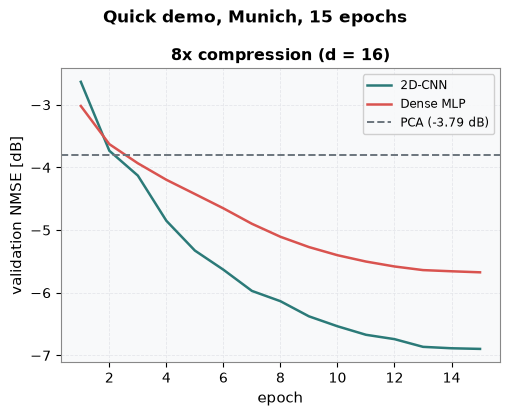

In [43]:
def plot_training_curves(results, latent_dims, title="", pca_key="PCA"):
    """Validation NMSE per epoch for each architecture, with the PCA test NMSE as a reference line."""
    fig, axes = plt.subplots(1, len(latent_dims), figsize=(5.2 * len(latent_dims), 4.2), squeeze=False, sharey=True)
    for ax, d in zip(axes[0], latent_dims):
        for a in ("CNN", "MLP"):
            if d in results.get(a, {}):
                h = results[a][d]["history"]["val_nmse_db"]
                ax.plot(range(1, len(h) + 1), h, color=COLORS[a], lw=1.8, label=MODEL_LABEL[a])
        pca = results[pca_key][d]["test_metrics"]["aggregate_nmse_db"]
        ax.axhline(pca, color=COLORS["PCA"], ls="--", lw=1.4, label=f"PCA ({pca:.2f} dB)")
        ax.set_title(f"{128 // d}x compression (d = {d})", fontweight="bold")
        ax.set_xlabel("epoch")
        ax.legend(fontsize=8.5)
    axes[0, 0].set_ylabel("validation NMSE [dB]")
    fig.suptitle(title, fontsize=12, fontweight="bold")
    plt.tight_layout()
    return fig


LIVE = {}                                        # live results by scene (demo or full re-training)
if RUN["quick_demo"] and "munich" in DATA:
    cfg_demo = replace(CFG["munich"], epochs=DEMO_EPOCHS)
    res, rec, X_te = run_experiment(cfg_demo, DATA["munich"], SPLITS["munich"], device, latent_dims=[16])
    LIVE["demo"] = {"results": res, "recon": rec, "X_test": X_te}
    plot_training_curves(res, [16], f"Quick demo, Munich, {DEMO_EPOCHS} epochs")
    plt.show()
else:
    print("Quick demo skipped (RUN['quick_demo'] is False or Munich data missing).")

**Reading the demo.** Both curves drop quickly during the first epochs while the learning rate is still high, then flatten; the cosine schedule makes the last epochs a fine-tuning phase. After only 15 epochs the networks are typically already close to (or beyond) the PCA level and still improving. 120 epochs are used for the reported results. A validation curve that *keeps decreasing* together with a stable training loss is the sign that we are not over-fitting.

## **10 · KPI tables (one row per model and compression ratio)**

The archived KPI tables come from my full runs (120 epochs, 3 latent sizes, 2 architectures + PCA, per city). Their column names changed between two versions of my pipeline, so the loader below maps both to one schema. With `RUN["training"] = True` the 12 autoencoders of every city in `TRAIN_SCENES` ("munich", "bologna" or "both") are re-trained here instead (the KPI table and the figures are saved in `results/`, the previous files being kept as `.bak`; slightly different numbers are normal: software versions, accelerator, non-deterministic operations).

In [44]:
_COLUMN_ALIASES = {
    "model": ["model", "architecture", "arch"],
    "d": ["latent_dim_d", "latent_dim", "d"],
    "nmse_db": ["overall_nmse_db", "aggregate_nmse_db", "nmse_db"],
    "median_nmse_db": ["median_nmse_db"],
    "p90_nmse_db": ["p90_nmse_db"],
    "cosine": ["mean_cosine_similarity", "cosine_similarity", "mean_rho"],
    "svd_ratio": ["svd_ratio", "mean_svd_ratio"],
    "params": ["num_params", "parameters", "params"],
    "train_time_s": ["train_time_s", "train_time_sec"],
    "infer_ms_per_ue": ["infer_ms_per_ue"],
}
_MODEL_NAMES = {"2d-cnn": "CNN", "cnn": "CNN", "dense-mlp": "MLP", "mlp": "MLP",
                "linear pca": "PCA", "linear-pca": "PCA", "pca": "PCA"}
KPI_COLUMNS = ["model", "d", "compression_ratio", "nmse_db", "median_nmse_db", "p90_nmse_db",
               "cosine", "svd_ratio", "params", "train_time_s", "infer_ms_per_ue"]


def load_kpi_table(cfg: ProjectConfig) -> Optional[pd.DataFrame]:
    """Read the archived KPI CSV of a scene and return it with the standard column names."""
    path = cfg.find_archived("csi_compression_metrics.csv")
    if path is None:
        print(f"[{cfg.scene_name}] no archived KPI table found.")
        return None
    raw = pd.read_csv(path)
    lower = {c.lower(): c for c in raw.columns}
    out = pd.DataFrame(index=raw.index)
    for std, aliases in _COLUMN_ALIASES.items():
        src = next((lower[a] for a in aliases if a in lower), None)
        out[std] = raw[src] if src is not None else np.nan
    if out["model"].isna().any() or out["d"].isna().any() or out["nmse_db"].isna().any():
        raise ValueError(f"Unexpected columns in {path}: {list(raw.columns)}")
    out["model"] = out["model"].astype(str).str.lower().map(_MODEL_NAMES)
    out["d"] = out["d"].astype(int)
    out["compression_ratio"] = 128 // out["d"]
    out = out[KPI_COLUMNS].sort_values(["model", "d"], ascending=[True, False]).reset_index(drop=True)
    return out


def results_to_frame(results, cfg: ProjectConfig) -> pd.DataFrame:
    """Same schema as load_kpi_table, built from a live run_experiment() output."""
    rows = []
    for model in ("CNN", "MLP", "PCA"):
        for d, r in results.get(model, {}).items():
            m = r["test_metrics"]
            rows.append({"model": model, "d": d, "compression_ratio": 128 // d, "nmse_db": m["aggregate_nmse_db"],
                         "median_nmse_db": m["median_nmse_db"], "p90_nmse_db": m["p90_nmse_db"],
                         "cosine": m["mean_rho"], "svd_ratio": m["mean_svd_ratio"], "params": r["num_params"],
                         "train_time_s": r["train_time_sec"], "infer_ms_per_ue": r["infer_ms_per_ue"]})
    return pd.DataFrame(rows, columns=KPI_COLUMNS).sort_values(["model", "d"], ascending=[True, False]).reset_index(drop=True)


KPI = {s: load_kpi_table(CFG[s]) for s in SCENES}
KPI = {s: t for s, t in KPI.items() if t is not None}

if RUN["training"]:                                   # full re-training of every city in TRAIN_SCENES (long)
    for scene in TRAIN_SCENES:
        if scene not in DATA:
            print(f"[{scene}] no dataset available, training skipped")
            continue
        print(f"=== re-training {CFG[scene].display_name} ===")
        res, rec, X_te = run_experiment(CFG[scene], DATA[scene], SPLITS[scene], device)
        LIVE[scene] = {"results": res, "recon": rec, "X_test": X_te}
        KPI[scene] = results_to_frame(res, CFG[scene])
        csv_path = CFG[scene].results_dir / f"{scene}_csi_compression_metrics.csv"      # KPI cache (previous file kept as .bak)
        save_with_backup(csv_path, lambda p: KPI[scene].to_csv(p, index=False))
        target, found = fig_paths(CFG[scene], "03_training_convergence.png")
        cached_figure(lambda: plot_training_curves(res, CFG[scene].latent_dims, f"{CFG[scene].display_name}: validation NMSE during training"),
                      target, found, force=True, show=False)
        print(f"-> KPI table saved to {csv_path}; the tables and figures below use the new results for {scene}")

# True when at least one city was re-trained in this session: its cached figures are stale and are redrawn
FRESH = any(s in LIVE for s in SCENES)

SHOW = ["model", "compression_ratio", "d", "nmse_db", "median_nmse_db", "p90_nmse_db", "cosine", "svd_ratio", "params", "train_time_s"]
for scene, table in KPI.items():
    print(f"\n{CFG[scene].display_name}  (test set, 750 UEs)")
    display(table[SHOW].style.format({"nmse_db": "{:.2f}", "median_nmse_db": "{:.2f}", "p90_nmse_db": "{:.2f}", "cosine": "{:.4f}",
                                      "svd_ratio": "{:.3f}", "params": "{:,.0f}", "train_time_s": "{:.1f}"}).hide(axis="index"))


Munich  (test set, 750 UEs)


model,compression_ratio,d,nmse_db,median_nmse_db,p90_nmse_db,cosine,svd_ratio,params,train_time_s
CNN,4,32,-13.31,-17.01,-9.62,nan,0.984,"141,810",80.1
CNN,8,16,-9.74,-12.79,-6.17,nan,0.960,"109,026",79.7
CNN,16,8,-6.74,-9.60,-2.21,nan,0.932,"92,634",80.0
MLP,4,32,-9.82,-12.97,-6.00,nan,0.927,"141,728",24.5
MLP,8,16,-9.08,-12.06,-5.04,nan,0.913,"137,616",24.7
MLP,16,8,-6.43,-8.58,-2.42,nan,0.849,"135,560",25.4
PCA,4,32,-7.07,-10.06,-2.56,nan,0.873,0,0.0
PCA,8,16,-3.79,-5.67,-0.15,nan,0.696,0,0.0
PCA,16,8,-2.09,-2.24,-0.03,nan,0.521,0,0.0



Bologna (Piazza Maggiore)  (test set, 750 UEs)


model,compression_ratio,d,nmse_db,median_nmse_db,p90_nmse_db,cosine,svd_ratio,params,train_time_s
CNN,4,32,-11.00,-16.00,-7.18,nan,0.978,"141,810",87.5
CNN,8,16,-8.41,-12.81,-4.37,nan,0.959,"109,026",79.5
CNN,16,8,-6.25,-9.70,-1.83,nan,0.915,"92,634",78.6
MLP,4,32,-8.63,-12.26,-4.17,nan,0.903,"141,728",25.1
MLP,8,16,-7.33,-10.68,-2.88,nan,0.880,"137,616",24.9
MLP,16,8,-5.45,-8.17,-1.07,nan,0.815,"135,560",24.4
PCA,4,32,-5.67,-8.66,-1.01,nan,0.807,0,0.0
PCA,8,16,-3.21,-3.88,-0.11,nan,0.636,0,0.0
PCA,16,8,-1.98,-0.74,-0.01,nan,0.490,0,0.0


**Reproducibility check.** (i) The PCA baseline recomputed live must reproduce the PCA rows of the KPI tables (same seed, same split, deterministic SVD) unless the dataset was re-generated or the tables were overwritten by a re-training; (ii) the parameter counts of the models instantiated in section 7 must match the archived ones.

In [45]:
print("(i) PCA live vs archived (aggregate NMSE, dB)")
for scene, table in KPI.items():
    if scene not in PCA_LIVE:
        continue
    for d, m in PCA_LIVE[scene].items():
        arch = float(table[(table.model == "PCA") & (table.d == d)].nmse_db.iloc[0])
        print(f"  {scene:8s} d={d:2d}: live {m['aggregate_nmse_db']:7.3f} | archived {arch:7.3f} | {'OK' if abs(m['aggregate_nmse_db'] - arch) < 0.05 else 'differs (expected if the dataset was re-generated)'}")

print("\n(ii) parameter counts vs archived")
for scene, table in list(KPI.items())[:1]:
    for model, cls in ARCHS.items():
        for d in CFG[scene].latent_dims:
            arch = table[(table.model == model) & (table.d == d)].params
            if len(arch) and arch.iloc[0] == arch.iloc[0]:
                n = count_params(cls(d))
                print(f"  {model} d={d:2d}: code {n:>8,} | archived {int(arch.iloc[0]):>8,} | {'OK' if n == int(arch.iloc[0]) else 'differs'}")

(i) PCA live vs archived (aggregate NMSE, dB)
  munich   d=32: live  -7.071 | archived  -7.071 | OK
  munich   d=16: live  -3.795 | archived  -3.795 | OK
  munich   d= 8: live  -2.092 | archived  -2.092 | OK
  bologna  d=32: live  -5.666 | archived  -5.666 | OK
  bologna  d=16: live  -3.210 | archived  -3.210 | OK
  bologna  d= 8: live  -1.975 | archived  -1.975 | OK

(ii) parameter counts vs archived
  CNN d=32: code  141,810 | archived  141,810 | OK
  CNN d=16: code  109,026 | archived  109,026 | OK
  CNN d= 8: code   92,634 | archived   92,634 | OK
  MLP d=32: code  141,728 | archived  141,728 | OK
  MLP d=16: code  137,616 | archived  137,616 | OK
  MLP d= 8: code  135,560 | archived  135,560 | OK


**Reading the tables.**
- **The CNN is the best model at every compression ratio, in both cities**, and every neural model beats PCA by a wide margin (≈ 3 to 7 dB): non-linear compression is worth it.
- **Aggregate vs. median.** The median NMSE is 3–5 dB better than the aggregate. Since every channel was normalised to the same energy, the aggregate NMSE is the *mean of the linear per-UE NMSE*, which is pulled up by the hardest UEs. Example (Munich, CNN 4×): median −17.3 dB, but the 10 % worst UEs are above −10.3 dB (p90). The two are not interchangeable: median = typical UE, aggregate = energy-weighted overall quality.
- **The MLP plateaus.** In Munich it goes from −9.03 dB (8×) to only −9.87 dB (4×): doubling the latent size barely helps, while the CNN improves by 4.6 dB. Hypothesis (not proven here): the MLP has no way to exploit the antenna-grid structure, so extra latent dimensions are not used efficiently.
- **Cost.** The CNN trains ≈ 4–5× slower than the MLP (≈ 55 s vs. 12 s for 120 epochs on my Apple GPU), but a forward pass is ~0.01–0.02 ms per UE: negligible at deployment.
- **Bologna is harder** than Munich at 4× (−10.1 vs. −13.9 dB for the CNN), the gap shrinking at 16×.

**Learning curves** (validation NMSE per epoch for the 120 epochs, dashed line = PCA; cached figure, redrawn after a re-training). They show that training converged for every $d$ (curves flatten as the cosine learning rate decays) and that both autoencoders pass the PCA level within the first epochs.

Munich


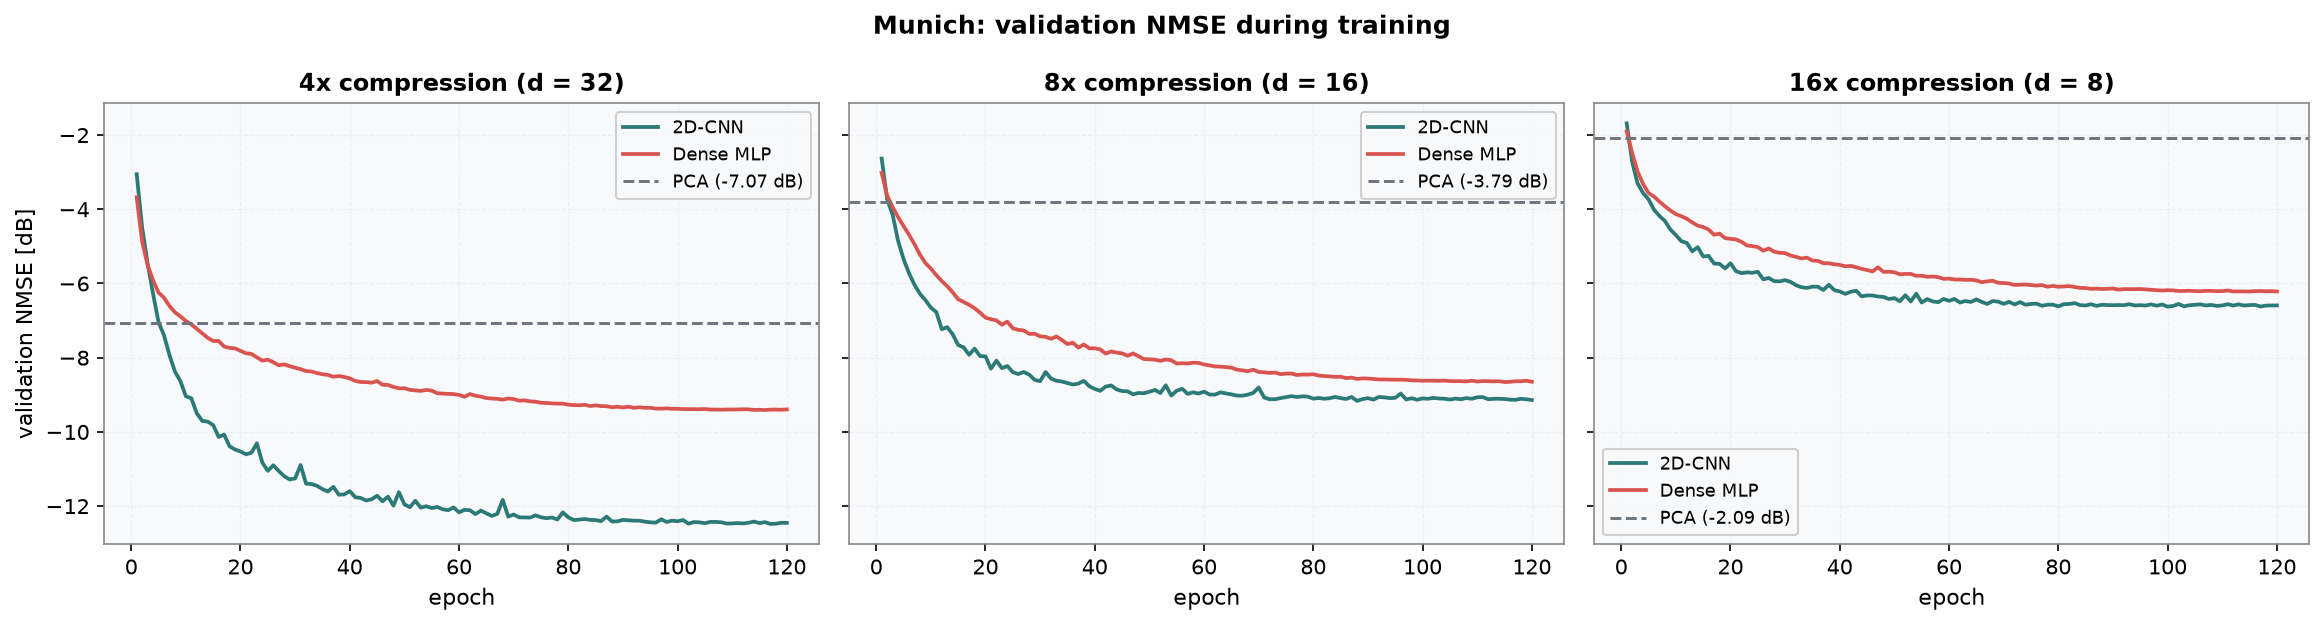

Bologna (Piazza Maggiore)


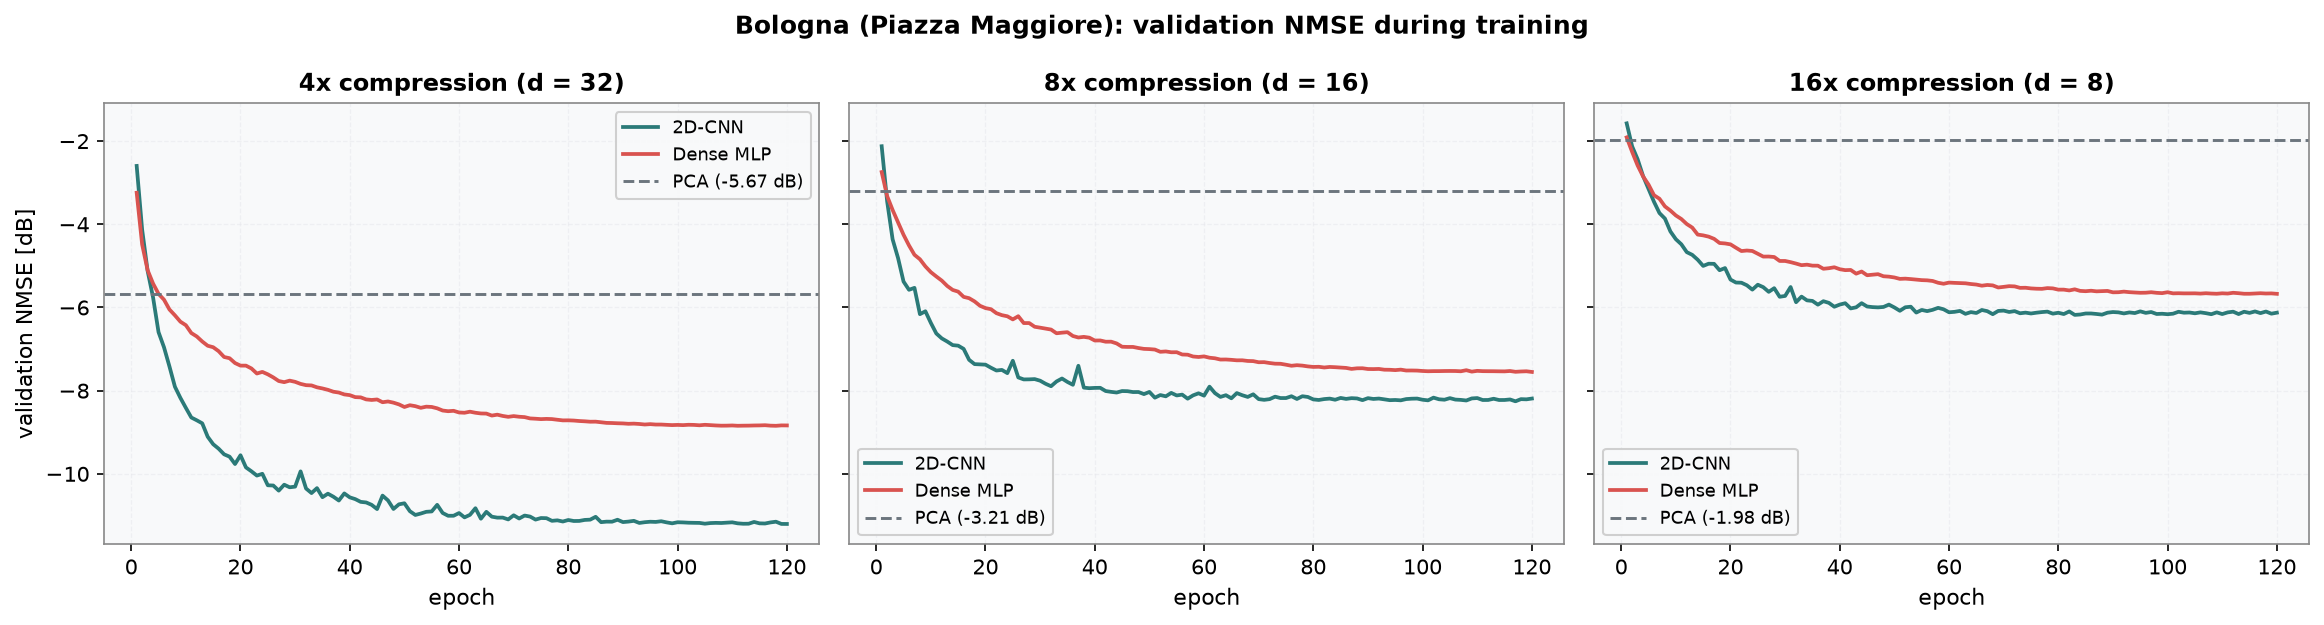

In [46]:
for scene in SCENES:
    print(CFG[scene].display_name)
    show_archived(CFG[scene], "03_training_convergence.png", width=1150)

## **11 · Deliverable 1 · Original |H| vs. reconstructed |Ĥ|**

One test UE (**#263** of the test set) is shown for each compression ratio. Rows: $d=32,16,8$ (4×, 8×, 16×). Columns: original, MLP, CNN. All panels share one colour scale; the title of each reconstruction gives that UE's NMSE. A second figure shows the **complex error** $|H-\hat H|$ (dark = good).

The figures come from the cache in `results/` (full 120-epoch runs); they are redrawn and re-saved after a re-training.

**Reading the heatmaps.**
- At **4×** the reconstructions reproduce the global pattern *and* many of the fine cells: bright and dark regions are at the right antenna pairs, and the error maps are almost uniformly dark.
- At **8×** and mostly at **16×** the fine, cell-to-cell variation is smoothed out (the codeword is too short to carry it) and the error concentrates in **clusters of antenna pairs** that carry strong, rapidly varying components. The strongest structures are what the network keeps.
- One UE is an **illustration, not a statistic**: the ranking of the MLP and the CNN on one UE can differ from the average one. The quantitative comparison is Deliverable 2 on the whole test set.

The same function can draw these maps live from any set of reconstructions. The function below draws them from the re-trained models (or from the quick-demo models if only the demo was run).

Munich


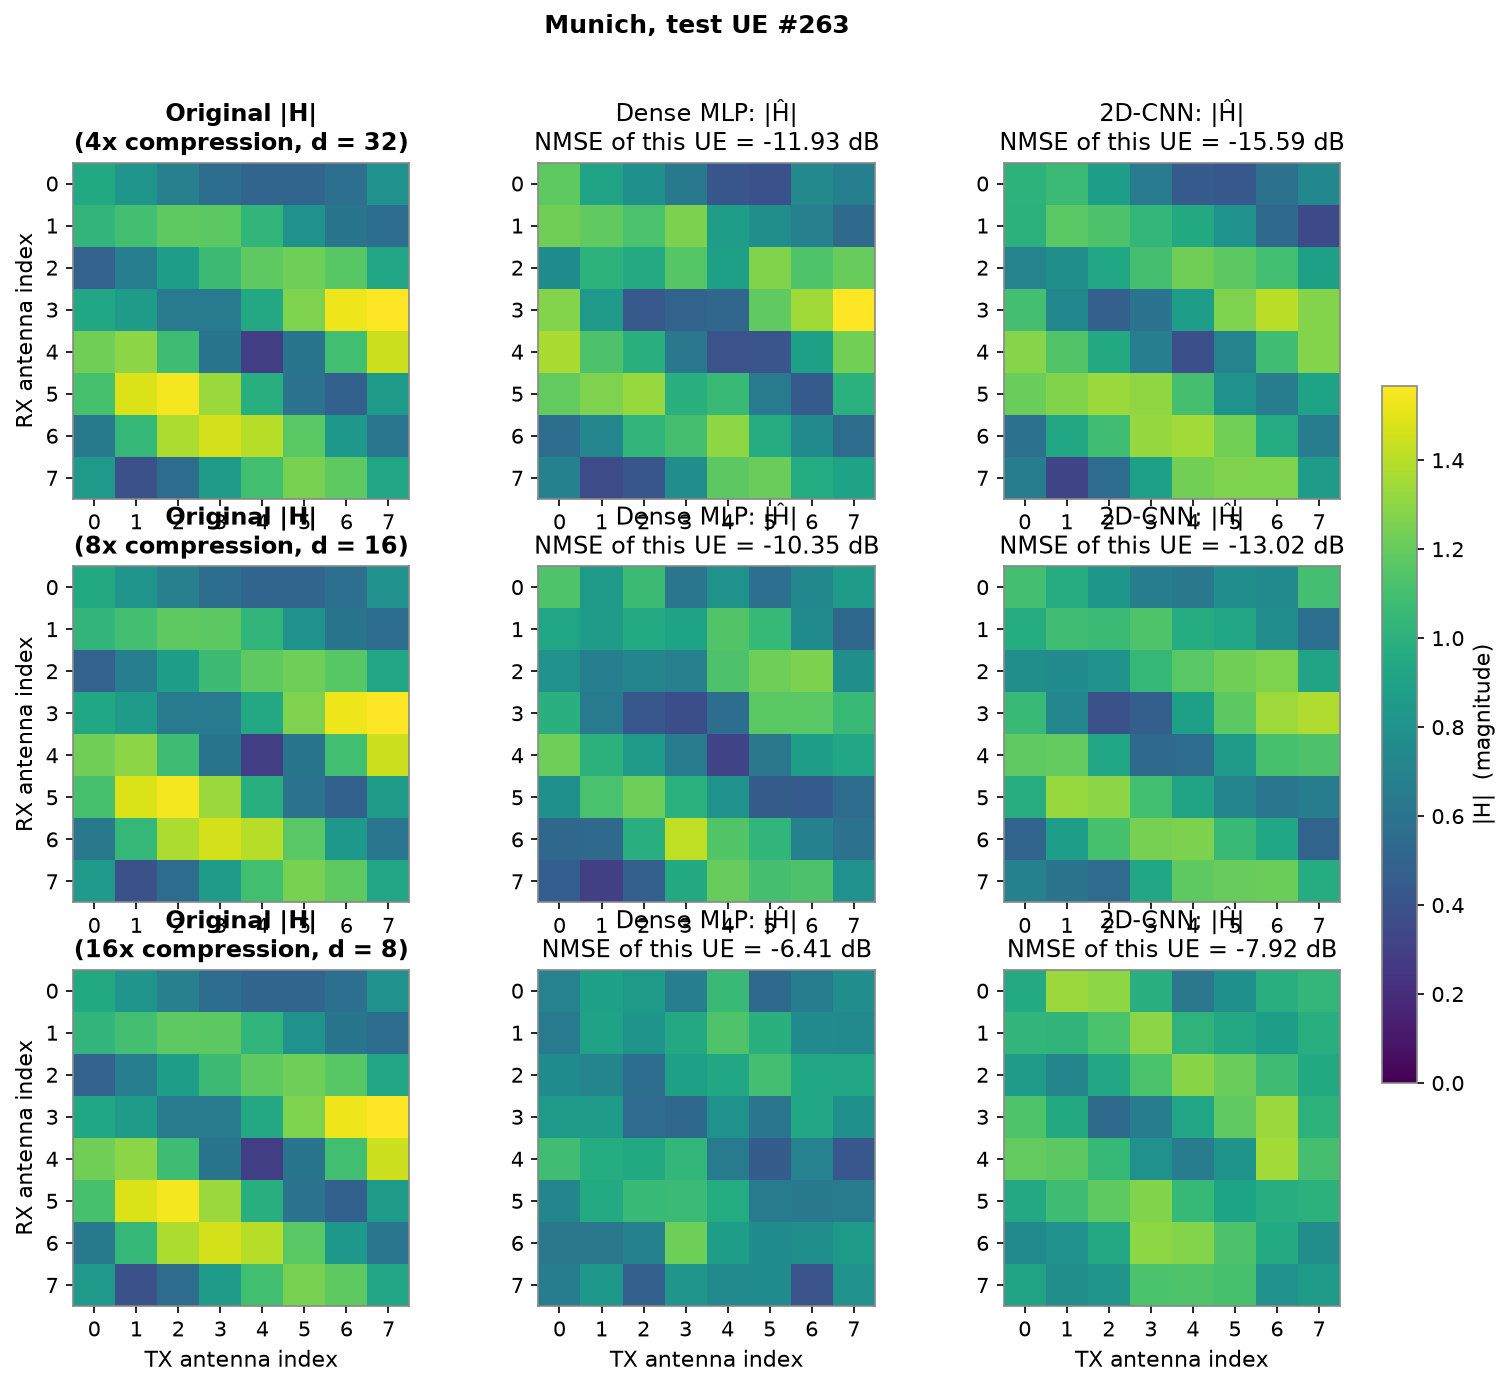

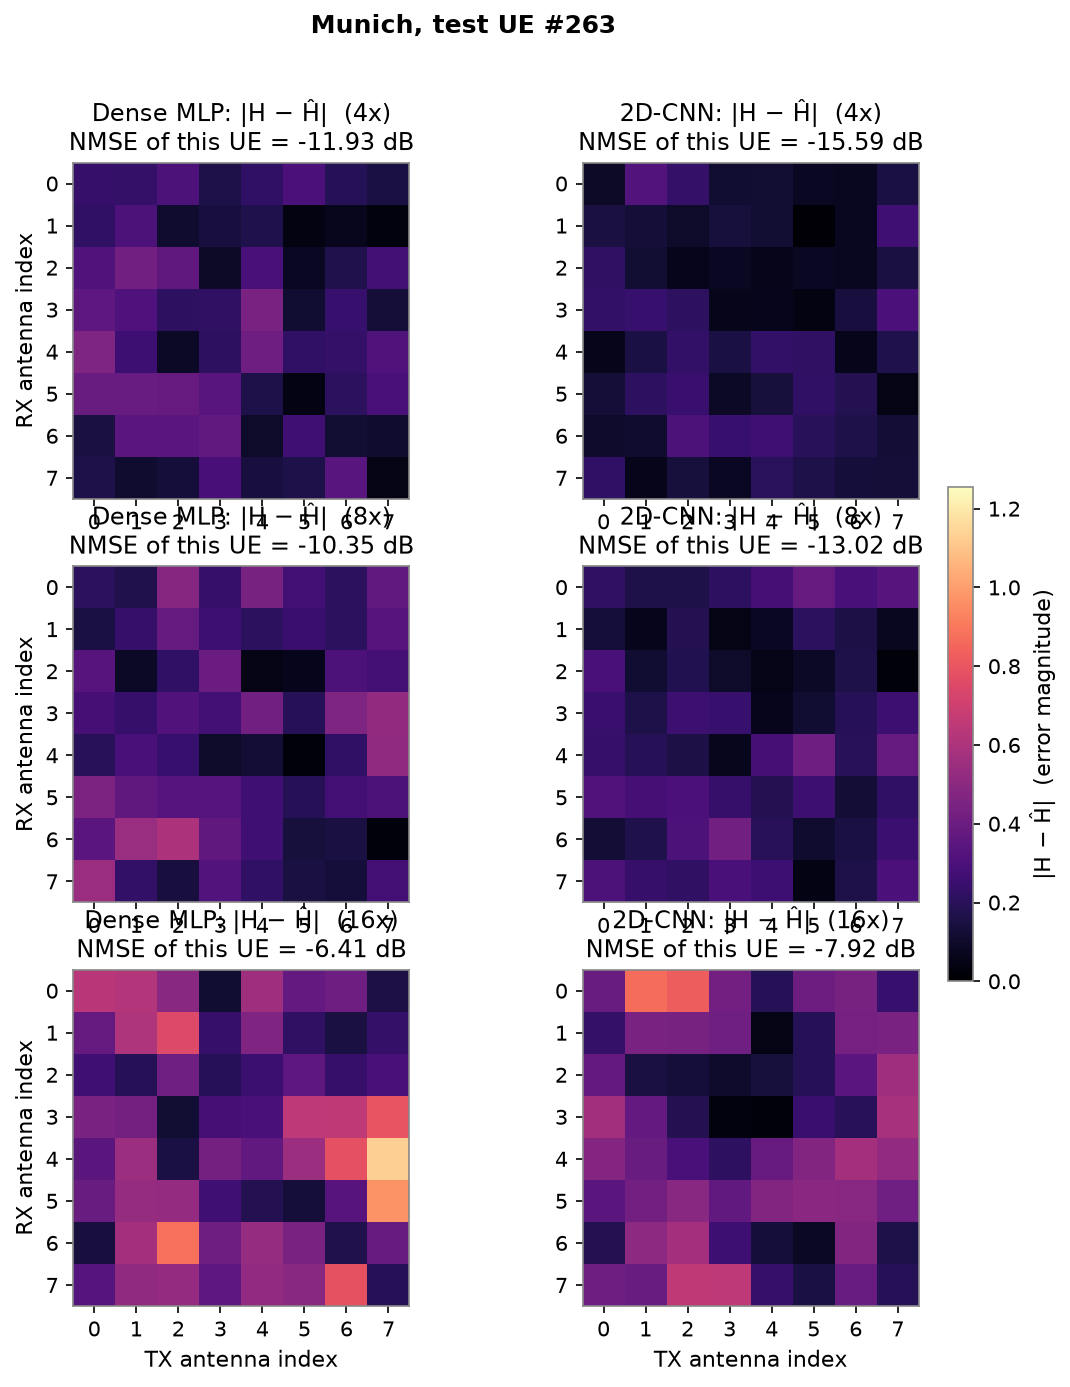

Bologna (Piazza Maggiore)


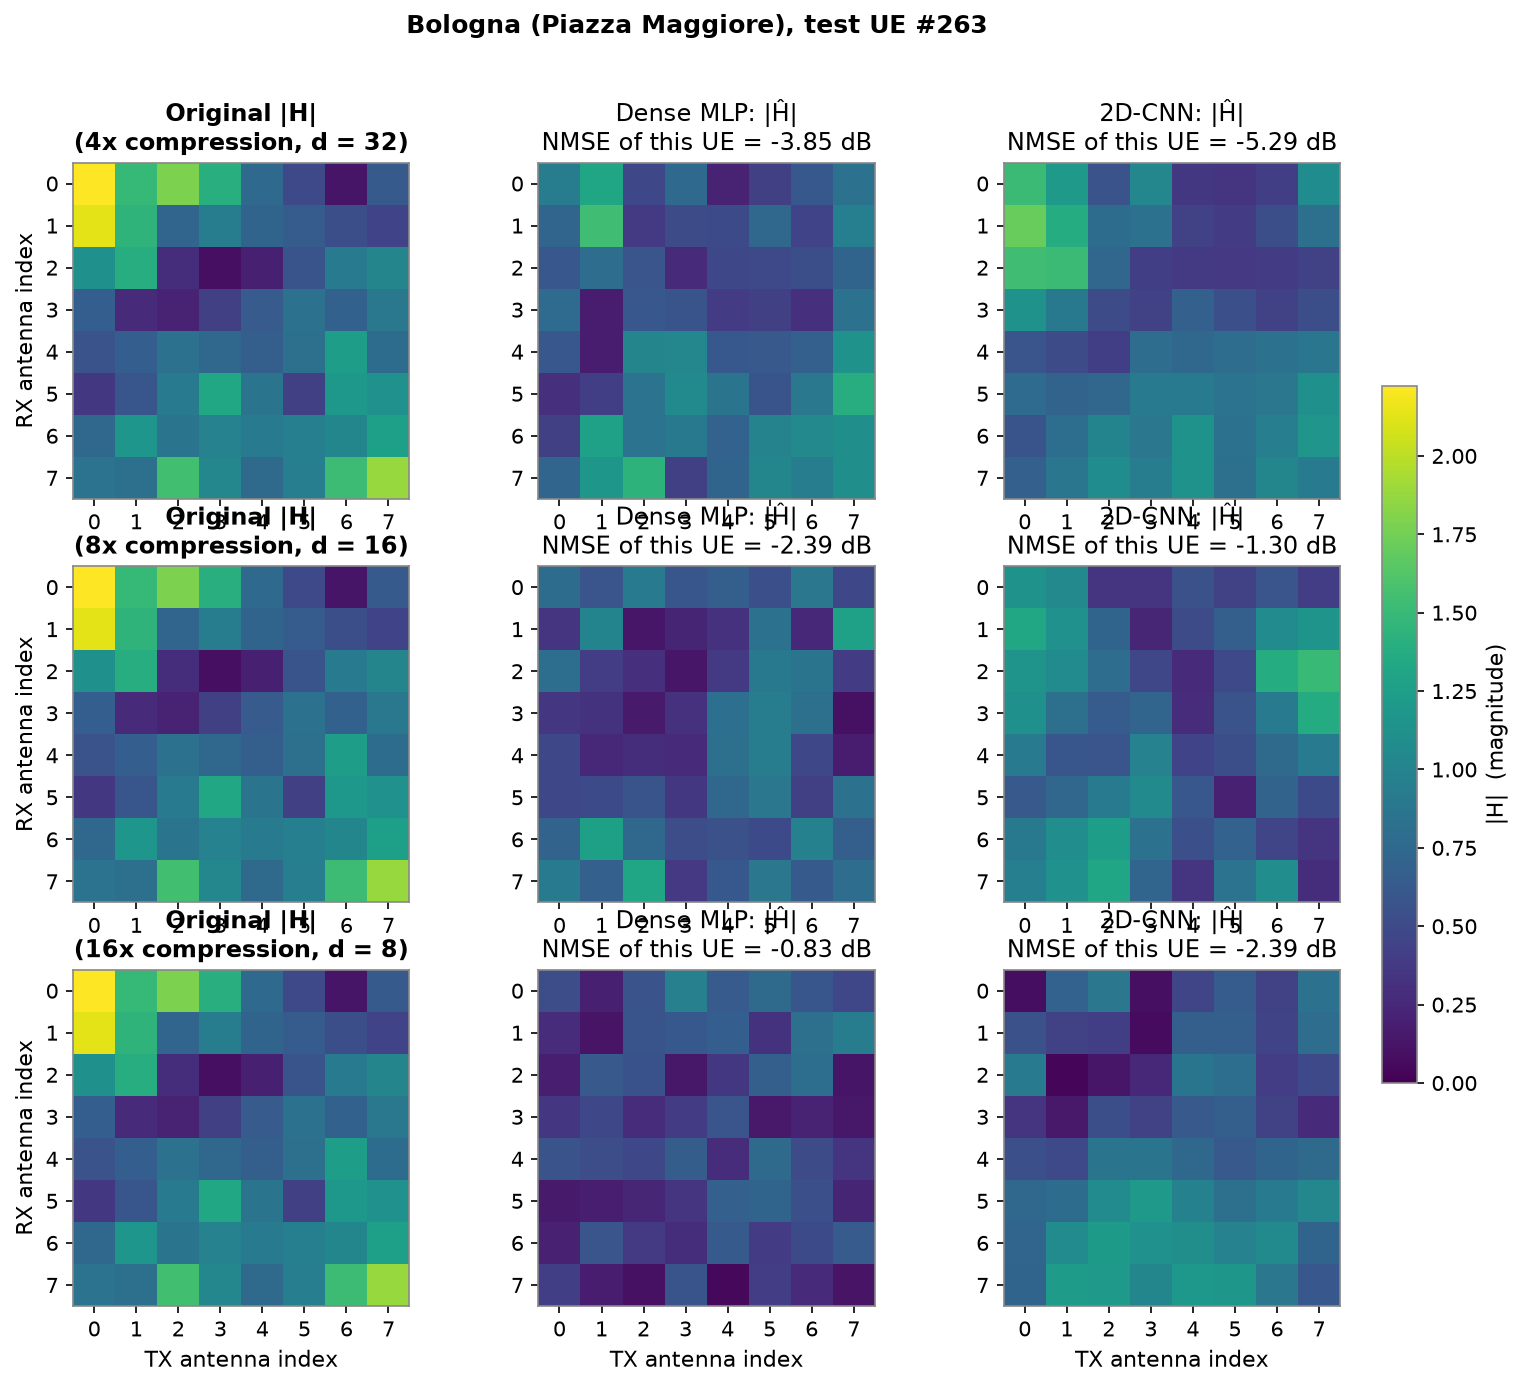

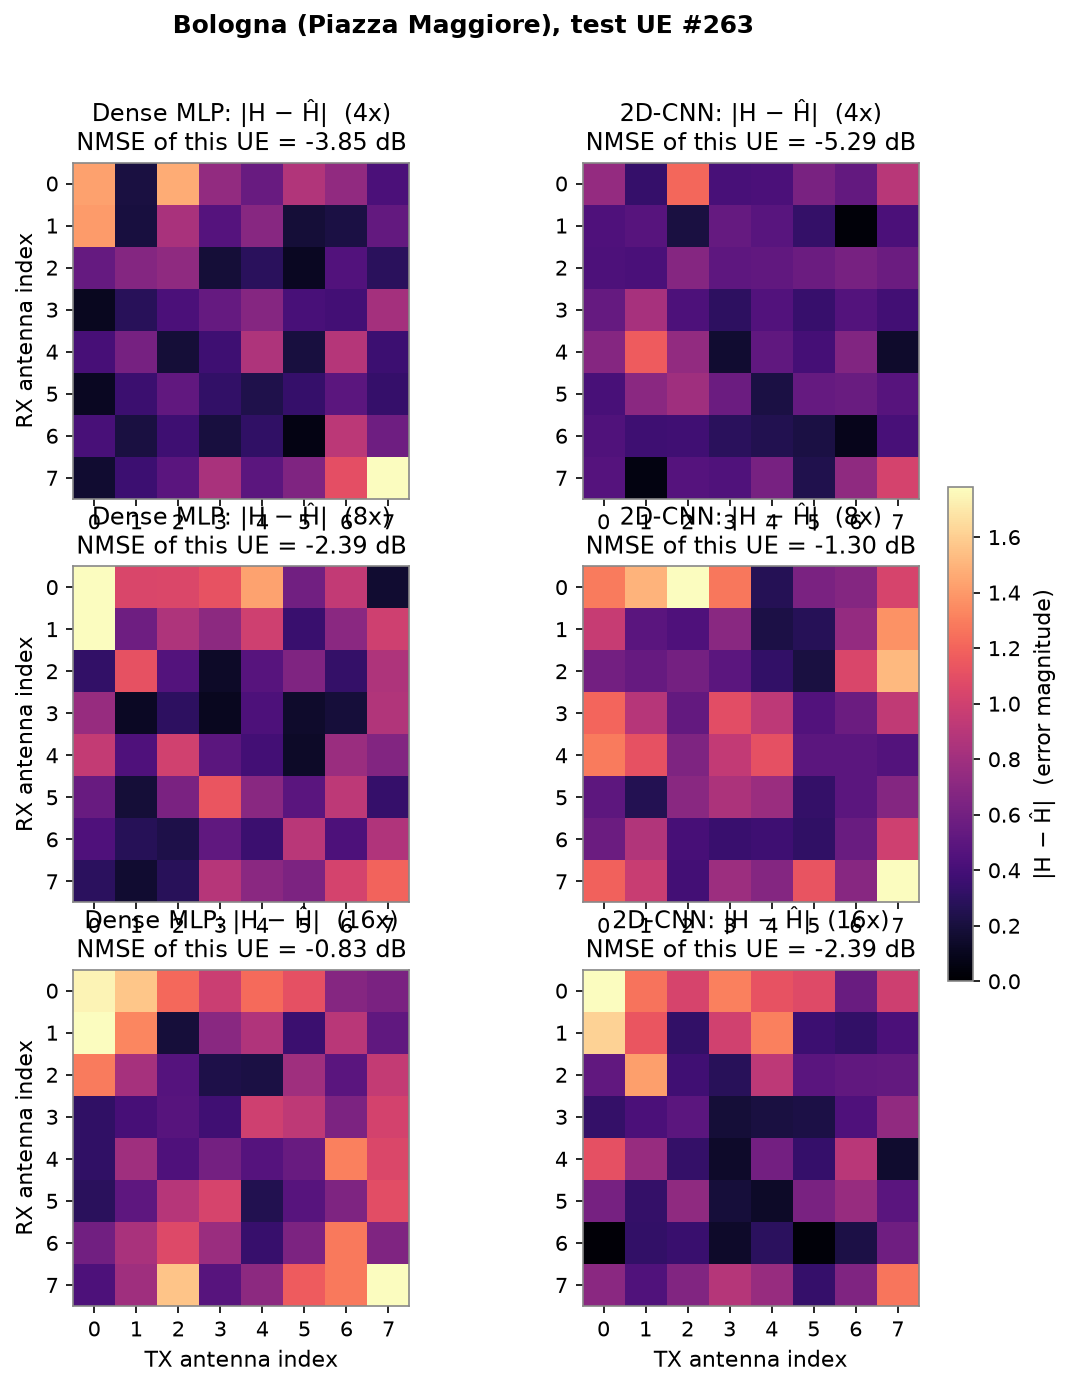

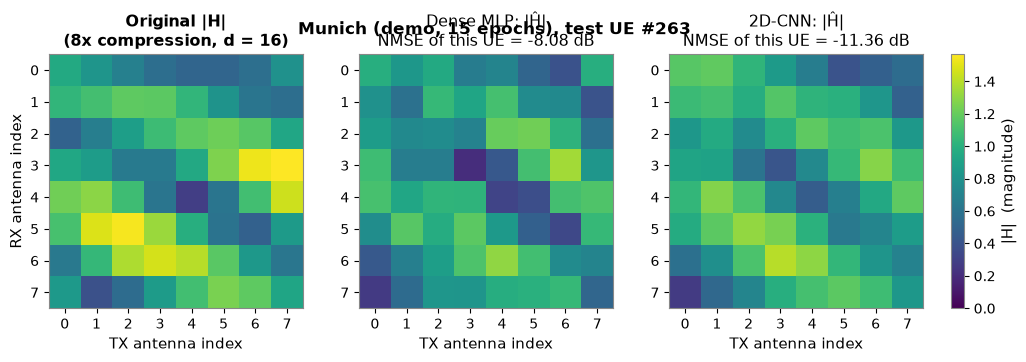

In [47]:
def plot_csi_heatmaps(X_test, recon, dims, kind="magnitude", sample_idx=263, title=""):
    """Deliverable 1. kind="magnitude": |H| next to |H_hat| of each model, one row per latent size; kind="error": |H - H_hat|."""
    sample_idx = min(sample_idx, len(X_test) - 1)
    archs = [a for a in ("MLP", "CNN") if a in recon]
    H = X_test[sample_idx, 0] + 1j * X_test[sample_idx, 1]
    vmax = float(np.percentile(np.abs(H), 99.5))

    def to_complex(x): return x[0] + 1j * x[1]

    ncols = 1 + len(archs) if kind == "magnitude" else len(archs)
    fig, axes = plt.subplots(len(dims), ncols, figsize=(3.5 * ncols + 1.5, 3.3 * len(dims)), squeeze=False)
    for r, d in enumerate(dims):
        if kind == "magnitude":
            im = axes[r, 0].imshow(np.abs(H), cmap="viridis", vmin=0, vmax=vmax)
            axes[r, 0].set_title(f"Original |H|\n({128 // d}x compression, d = {d})", fontweight="bold")
        for c, a in enumerate(archs, start=0 if kind == "error" else 1):
            H_hat = to_complex(recon[a][d][sample_idx])
            nmse = 10 * np.log10(max(np.sum(np.abs(H - H_hat) ** 2) / np.sum(np.abs(H) ** 2), 1e-12))
            if kind == "magnitude":
                im = axes[r, c].imshow(np.abs(H_hat), cmap="viridis", vmin=0, vmax=vmax)
                axes[r, c].set_title(f"{MODEL_LABEL[a]}: |Ĥ|\nNMSE of this UE = {nmse:.2f} dB")
            else:
                im = axes[r, c].imshow(np.abs(H - H_hat), cmap="magma", vmin=0, vmax=0.8 * vmax)
                axes[r, c].set_title(f"{MODEL_LABEL[a]}: |H − Ĥ|  ({128 // d}x)\nNMSE of this UE = {nmse:.2f} dB")
    for ax in axes.flat:
        ax.grid(False); ax.set_xticks(range(8)); ax.set_yticks(range(8))
    for ax in axes[-1]:
        ax.set_xlabel("TX antenna index")
    for ax in axes[:, 0]:
        ax.set_ylabel("RX antenna index")
    fig.colorbar(im, ax=axes, fraction=0.025, pad=0.03, label="|H|  (magnitude)" if kind == "magnitude" else "|H − Ĥ|  (error magnitude)")
    fig.suptitle(f"{title}, test UE #{sample_idx}", fontsize=12, fontweight="bold")
    return fig


HEATMAP_FILES = [("magnitude", "04_heatmaps_original_vs_reconstructed.png"), ("error", "04b_heatmaps_complex_error.png")]
for scene in SCENES:
    print(CFG[scene].display_name)
    live = scene in LIVE                                   # freshly re-trained: redraw, otherwise show the cached figure
    for kind, name in HEATMAP_FILES:
        target, found = fig_paths(CFG[scene], name)
        cached_figure(lambda: plot_csi_heatmaps(LIVE[scene]["X_test"], LIVE[scene]["recon"], CFG[scene].latent_dims, kind,
                                                title=CFG[scene].display_name),
                      target, found, force=live, can_draw=live, width=1000)
if not FRESH and "demo" in LIVE:                           # quick demo (not cached)
    plot_csi_heatmaps(LIVE["demo"]["X_test"], LIVE["demo"]["recon"], [16], title=f"Munich (demo, {DEMO_EPOCHS} epochs)")
    plt.show()

## **12 · Deliverable 2 · NMSE (dB) vs. compression ratio $D/d$**

Drawn **live** from the KPI tables, one panel per city: dense MLP vs. 2D-CNN (and the PCA baseline for reference). Lower is better. The right-hand figure uses the cosine similarity, the "beamforming-oriented" metric.

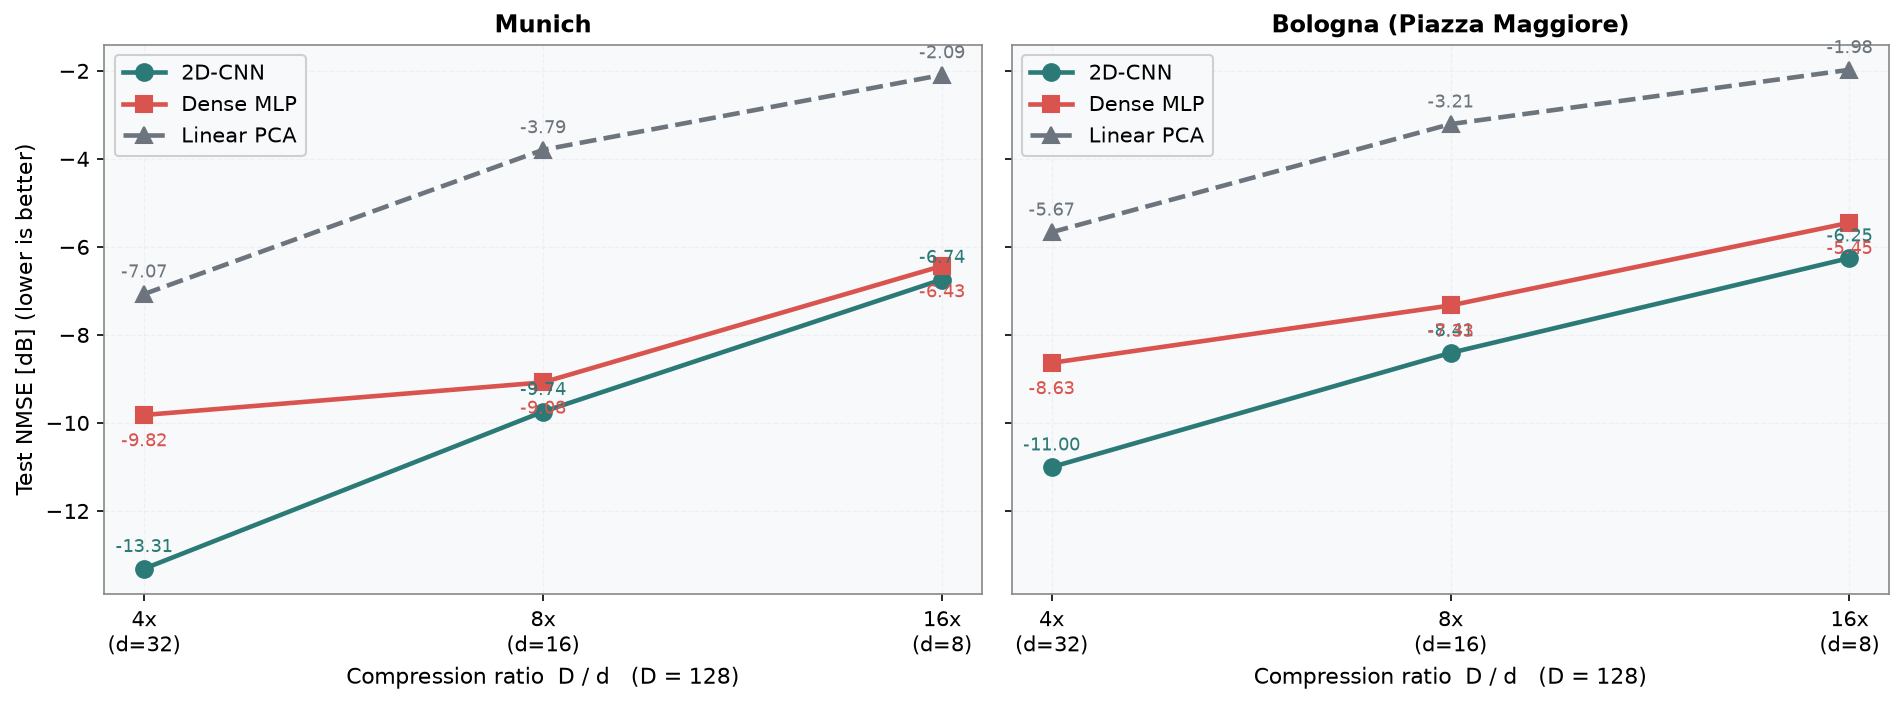

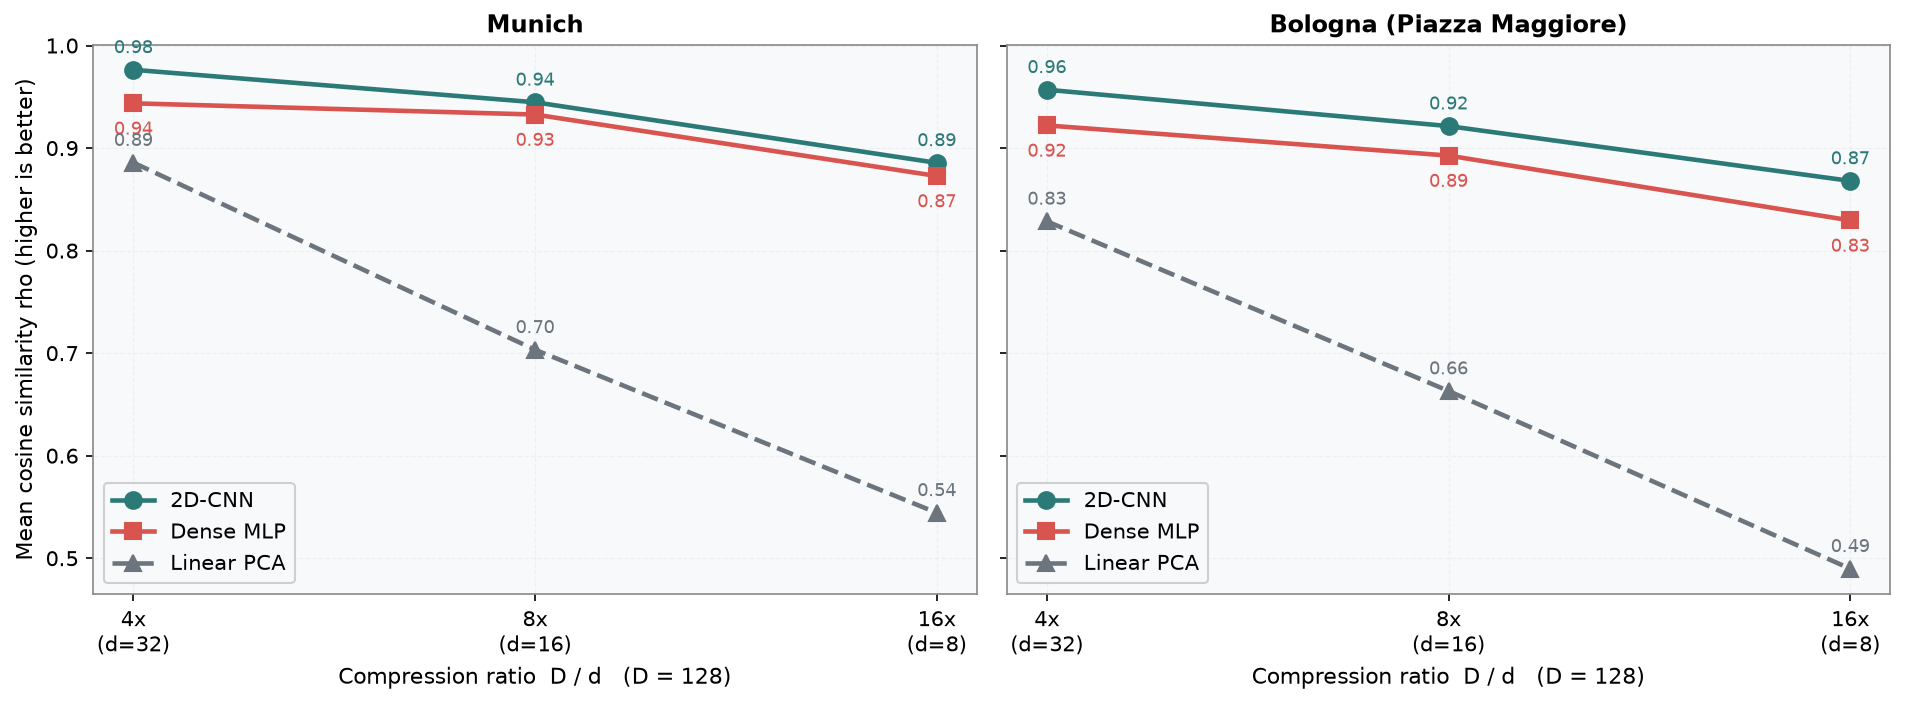

In [48]:
def plot_metric_vs_cr(tables: Dict[str, pd.DataFrame], metric: str = "nmse_db", ylabel: str = "Test NMSE [dB] (lower is better)"):
    """One panel per city: metric vs. compression ratio D/d for CNN, MLP and PCA."""
    fig, axes = plt.subplots(1, len(tables), figsize=(6.4 * len(tables), 4.8), squeeze=False, sharey=True)
    styles = {"CNN": "o-", "MLP": "s-", "PCA": "^--"}
    for ax, (scene, table) in zip(axes[0], tables.items()):
        for model in ("CNN", "MLP", "PCA"):
            sub = table[table.model == model].sort_values("compression_ratio")
            ax.plot(sub.compression_ratio, sub[metric], styles[model], color=COLORS[model], lw=2.2, ms=8, label=MODEL_LABEL[model])
            for cr, v in zip(sub.compression_ratio, sub[metric]):
                ax.annotate(f"{v:.2f}", (cr, v), textcoords="offset points", xytext=(0, 8 if model != "MLP" else -15),
                            ha="center", fontsize=8.5, color=COLORS[model])
        ax.set_xscale("log", base=2)
        ax.set_xticks([4, 8, 16]); ax.set_xticklabels(["4x\n(d=32)", "8x\n(d=16)", "16x\n(d=8)"])
        ax.minorticks_off()
        ax.set_xlabel("Compression ratio  D / d   (D = 128)")
        ax.set_title(CFG[scene].display_name, fontweight="bold")
        ax.legend(loc="best")
    axes[0, 0].set_ylabel(ylabel)
    plt.tight_layout()
    return fig


for metric, ylabel, fname in [("nmse_db", "Test NMSE [dB] (lower is better)", "08_deliverable2_nmse_vs_compression_ratio.png"),
                              ("cosine", "Mean cosine similarity rho (higher is better)", "09_cosine_vs_compression_ratio.png")]:
    cached_figure(lambda: plot_metric_vs_cr(KPI, metric, ylabel), CFG["munich"].results_dir / fname, force=FRESH)

In [49]:
def gain_table(table: pd.DataFrame) -> pd.DataFrame:
    """Improvement of the CNN [dB of NMSE] over PCA and over the MLP, per compression ratio."""
    p = table.pivot(index="compression_ratio", columns="model", values="nmse_db")
    return pd.DataFrame({"CNN gain vs PCA [dB]": p["PCA"] - p["CNN"], "CNN gain vs MLP [dB]": p["MLP"] - p["CNN"],
                         "MLP gain vs PCA [dB]": p["PCA"] - p["MLP"]}).round(2)


for scene, table in KPI.items():
    print(CFG[scene].display_name)
    display(gain_table(table))

Munich


,CNN gain vs PCA [dB],CNN gain vs MLP [dB],MLP gain vs PCA [dB]
compression_ratio,,,
4,6.24,3.49,2.75
8,5.95,0.67,5.28
16,4.65,0.31,4.34


Bologna (Piazza Maggiore)


,CNN gain vs PCA [dB],CNN gain vs MLP [dB],MLP gain vs PCA [dB]
compression_ratio,,,
4,5.34,2.37,2.97
8,5.20,1.08,4.12
16,4.28,0.80,3.48


**Reading Deliverable 2.**
- **All curves degrade with compression**: the more aggressive the bottleneck, the larger the NMSE, as expected from a rate–distortion trade-off. Cosine similarity falls too, but gently for the networks (CNN: 0.98 → 0.90 in Munich) and dramatically for PCA (0.89 → 0.54): a 16× PCA feedback would give a beamformer almost unrelated to the real channel.
- **CNN vs. PCA: 4.4–6.8 dB in every case**: i.e. the CNN loses a factor 3 to 5 less energy. This is the value of non-linear, structure-aware compression.
- **CNN vs. MLP depends on the city and the ratio.** The advantage is large only at Munich 4× (+4.0 dB). At 8× and 16× it is small in Munich (+0.2 / +0.4 dB: the two curves almost touch) but stays ≈ +1 dB in Bologna. So the architecture matters most when the bottleneck is wide enough to carry structure; when it is tight, the latent size dominates.
- **Both models are far from "perfect"**: even the best curve at 16× is at −7 dB (≈ 20 % energy lost). The compression ratio is a ratio of real dimensions *without quantisation*; a real feedback would be worse (limitation 4).

Complementary figure: left = same NMSE curve, middle = **empirical CDF of the per-UE NMSE** (the whole distribution, not just the mean: the CNN curves are shifted to the left, and every curve has a long right tail of hard UEs), right = cosine similarity.

Munich


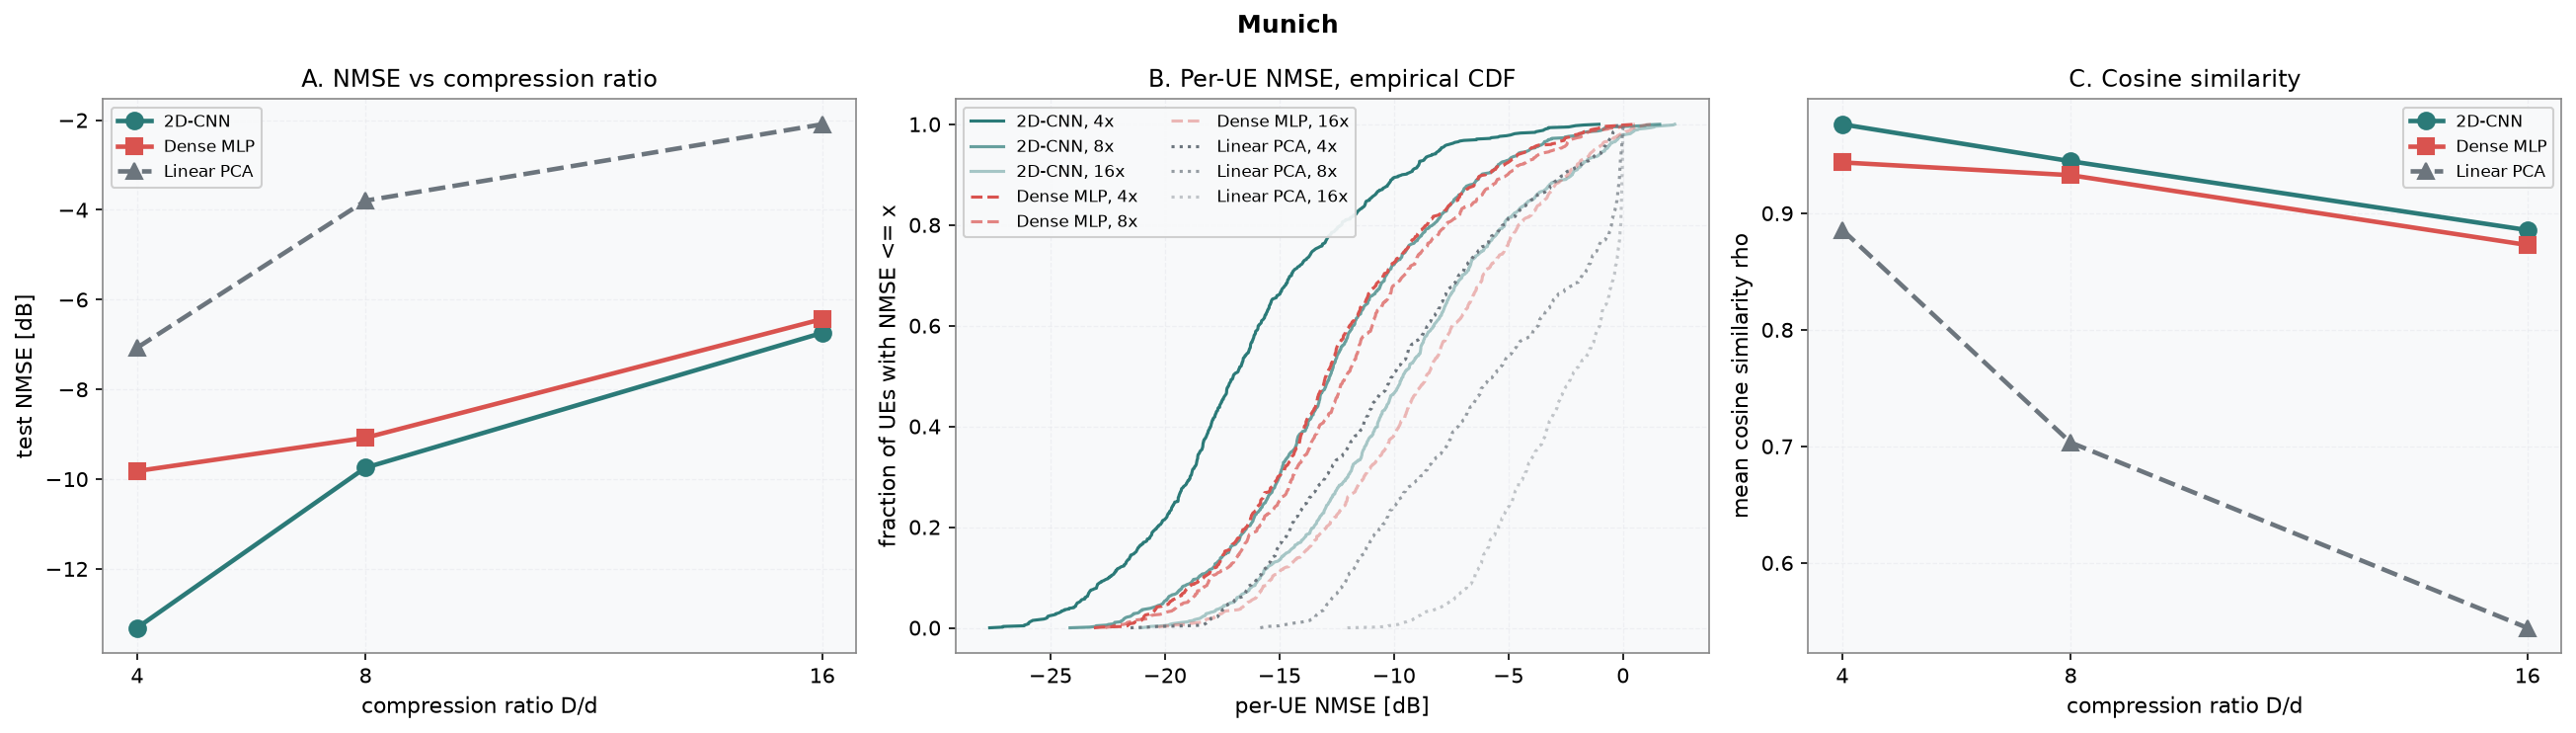

Bologna (Piazza Maggiore)


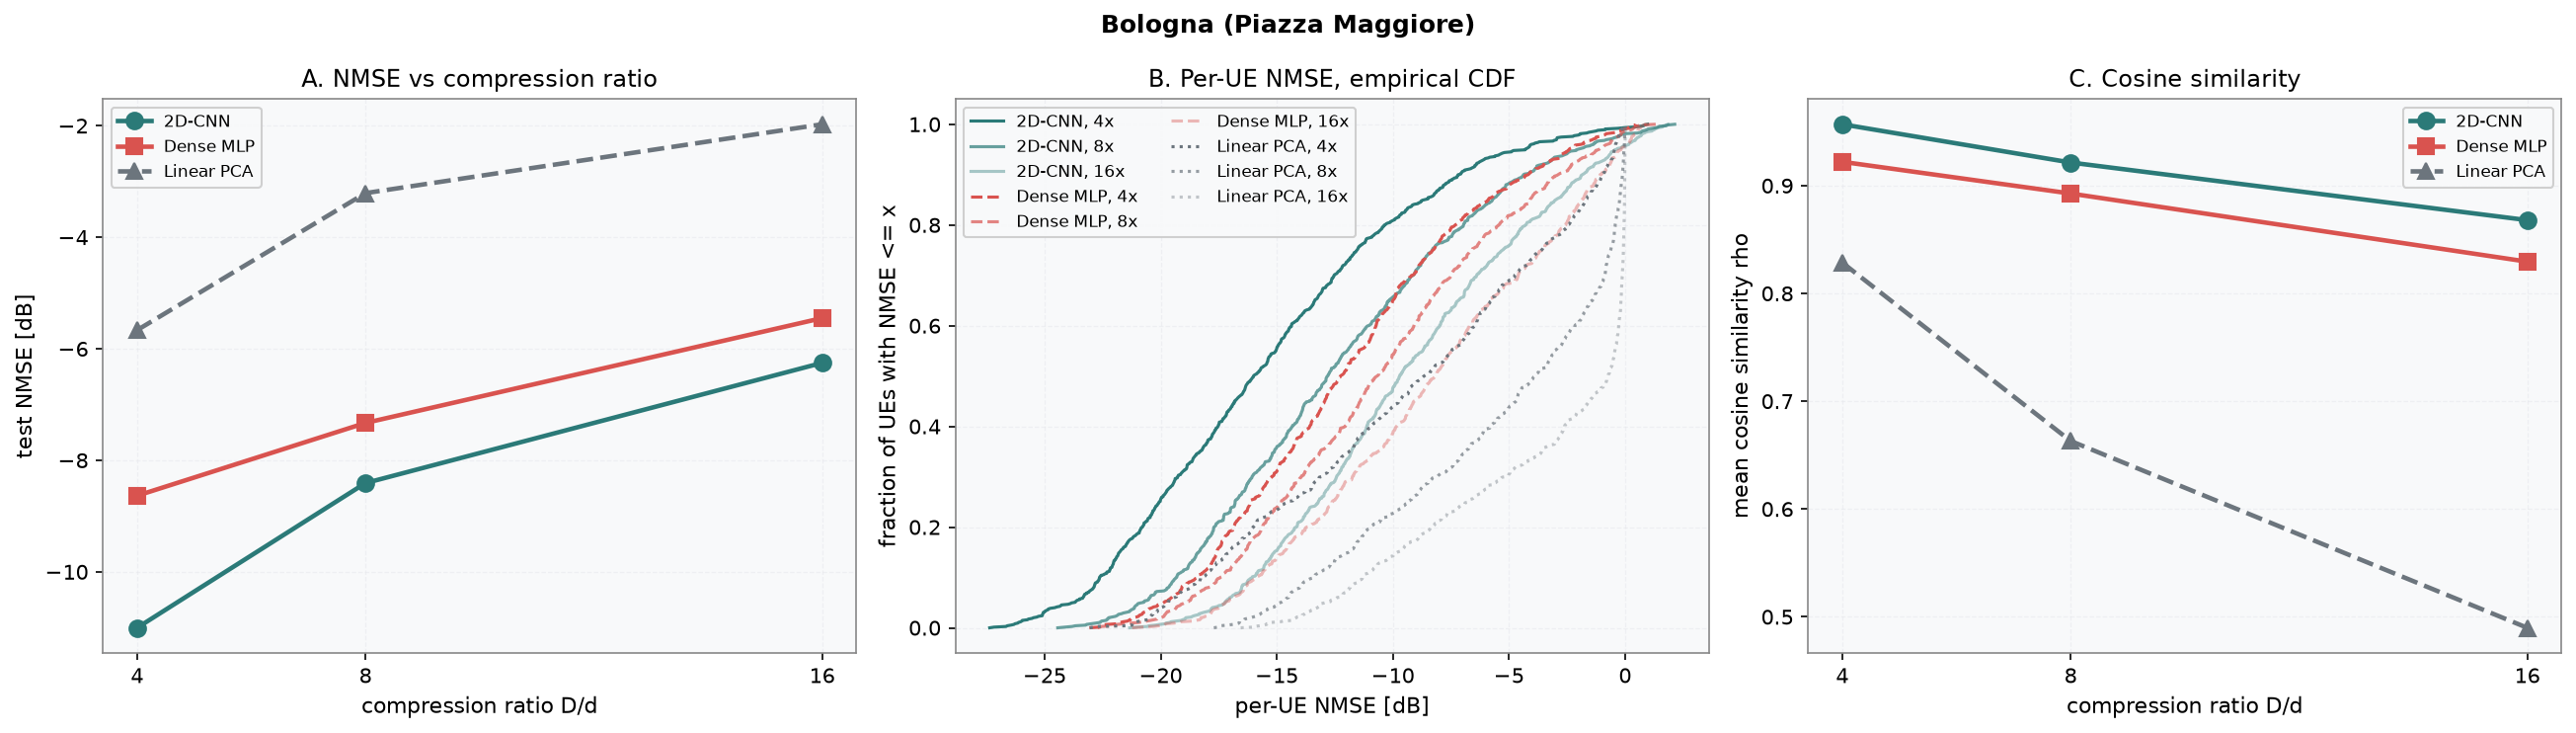

In [50]:
def plot_summary_panels(results, dims, title=""):
    """Left: NMSE vs compression ratio. Middle: empirical CDF of the per-UE NMSE. Right: cosine similarity."""
    crs = [128 // d for d in dims]
    fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.0))
    styles = {"CNN": "o-", "MLP": "s-", "PCA": "^--"}
    for m in ("CNN", "MLP", "PCA"):
        axes[0].plot(crs, [results[m][d]["test_metrics"]["aggregate_nmse_db"] for d in dims], styles[m],
                     color=COLORS[m], lw=2.2, ms=8, label=MODEL_LABEL[m])
        axes[2].plot(crs, [results[m][d]["test_metrics"]["mean_rho"] for d in dims], styles[m],
                     color=COLORS[m], lw=2.2, ms=8, label=MODEL_LABEL[m])
        for d, alpha in zip(dims, (1.0, 0.7, 0.4)):
            v = np.sort(results[m][d]["test_metrics"]["nmse_db_per_sample"])
            axes[1].plot(v, np.linspace(0, 1, len(v)), color=COLORS[m], alpha=alpha, ls={"CNN": "-", "MLP": "--", "PCA": ":"}[m],
                         label=f"{MODEL_LABEL[m]}, {128 // d}x")
    axes[0].set(title="A. NMSE vs compression ratio", xlabel="compression ratio D/d", ylabel="test NMSE [dB]", xticks=crs)
    axes[1].set(title="B. Per-UE NMSE, empirical CDF", xlabel="per-UE NMSE [dB]", ylabel="fraction of UEs with NMSE <= x")
    axes[2].set(title="C. Cosine similarity", xlabel="compression ratio D/d", ylabel="mean cosine similarity rho", xticks=crs)
    for ax in axes:
        ax.legend(fontsize=8, ncol=2 if ax is axes[1] else 1)
    fig.suptitle(title, fontsize=12, fontweight="bold")
    plt.tight_layout()
    return fig


for scene in SCENES:
    print(CFG[scene].display_name)
    live = scene in LIVE
    target, found = fig_paths(CFG[scene], "05_nmse_vs_compression_ratio.png")
    cached_figure(lambda: plot_summary_panels(LIVE[scene]["results"], CFG[scene].latent_dims, CFG[scene].display_name),
                  target, found, force=live, can_draw=live, width=1250)

## **13 · Munich vs. Bologna**

Same code, same hyper-parameters, two different urban environments. Left: distribution of the number of paths per UE; middle: CDF of the radio-map path gain at the sampled UEs; right: CNN NMSE for both cities. All **live** (from the caches and KPI tables).

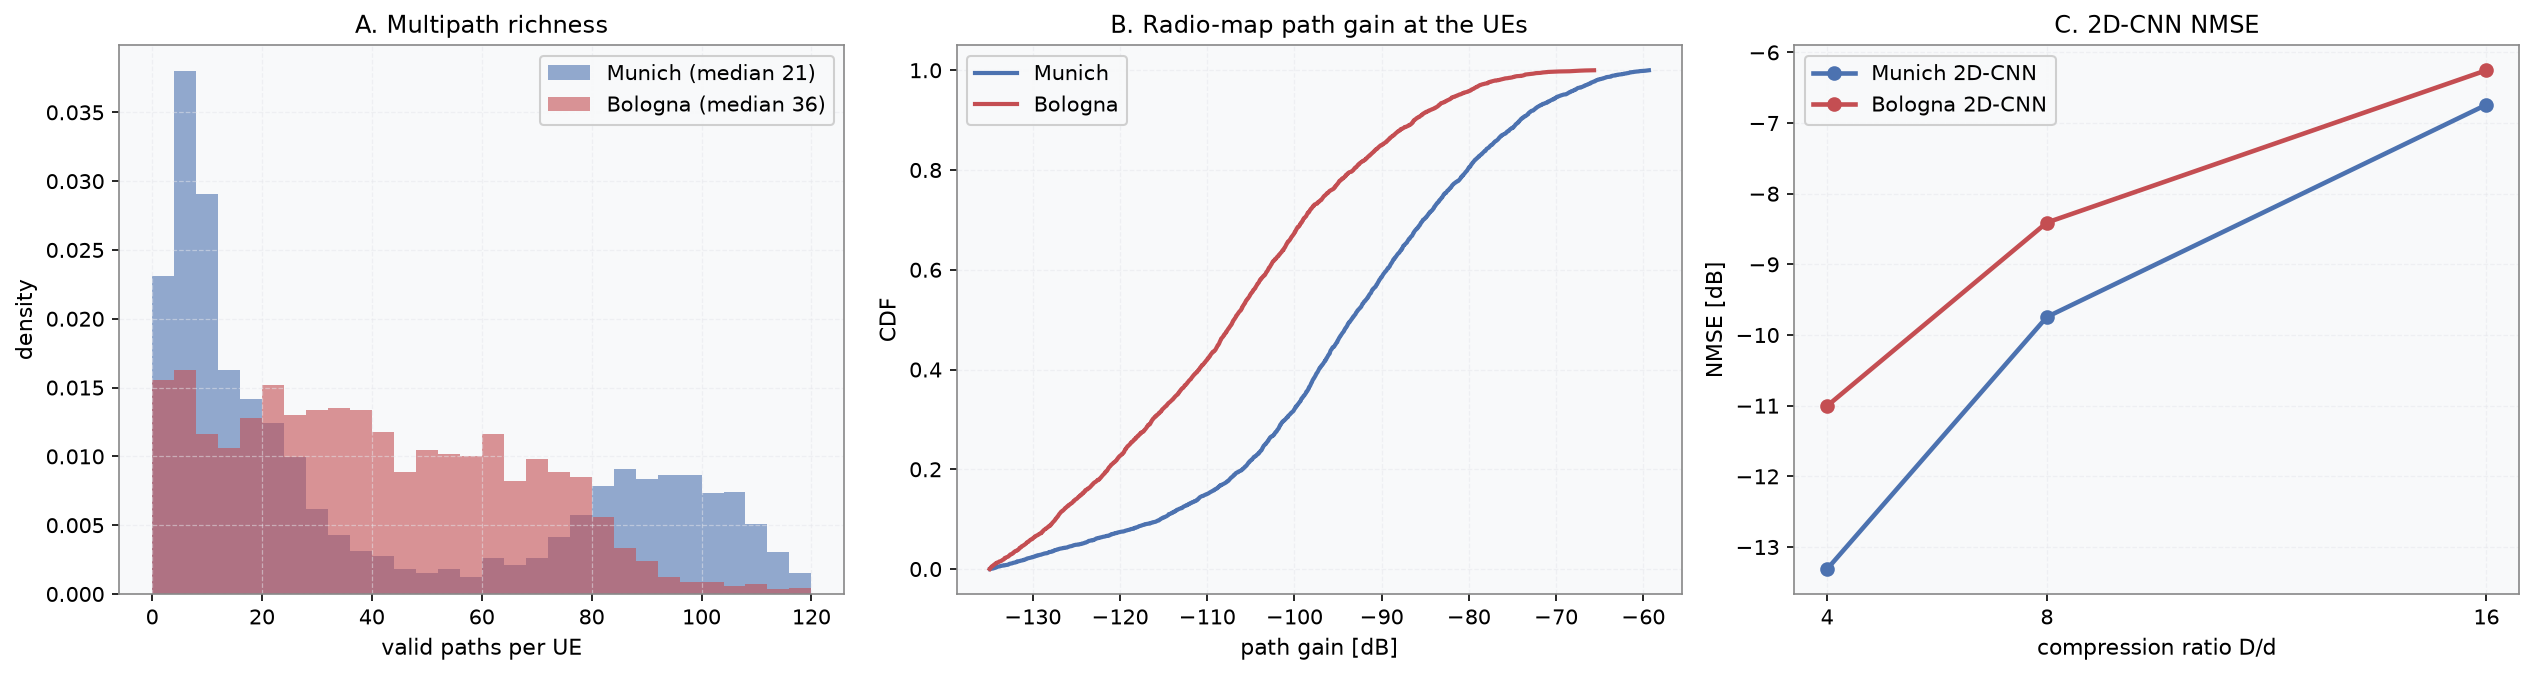

In [51]:
def plot_city_comparison(data: Dict[str, dict], tables: Dict[str, pd.DataFrame]):
    colors = {"munich": "#4C72B0", "bologna": "#C44E52"}
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    for s, d in data.items():
        axes[0].hist(d["num_paths"], bins=30, range=(0, 120), alpha=0.6, density=True, color=colors[s],
                     label=f"{CFG[s].display_name.split(' ')[0]} (median {int(np.median(d['num_paths']))})")
        pg = np.sort(d["rm_path_gain_db"])
        axes[1].plot(pg, np.linspace(0, 1, len(pg)), color=colors[s], lw=2, label=CFG[s].display_name.split(" ")[0])
    axes[0].set(title="A. Multipath richness", xlabel="valid paths per UE", ylabel="density")
    axes[1].set(title="B. Radio-map path gain at the UEs", xlabel="path gain [dB]", ylabel="CDF")
    for s, t in tables.items():
        cnn = t[t.model == "CNN"].sort_values("compression_ratio")
        axes[2].plot(cnn.compression_ratio, cnn.nmse_db, "o-", color=colors[s], lw=2.2, label=f"{CFG[s].display_name.split(' ')[0]} 2D-CNN")
    axes[2].set(title="C. 2D-CNN NMSE", xlabel="compression ratio D/d", ylabel="NMSE [dB]", xticks=[4, 8, 16])
    for ax in axes:
        ax.legend()
    plt.tight_layout()
    return fig


if len(DATA) == 2 and len(KPI) == 2:
    cached_figure(lambda: plot_city_comparison(DATA, KPI), CFG["munich"].results_dir / "07_comparison_munich_vs_bologna.png",
                  force=FRESH or RUN["ray_tracing"], width=1250)
else:
    print("Both cities are needed for the comparison.")

**Reading the comparison.**
- Bologna has a **richer multipath** (median 36 vs. 21 paths) and a **lower path gain** (denser blocks, narrower streets, so more attenuation).
- The CNN reconstructs Munich better at 4× (−13.9 vs. −10.1 dB) and the gap narrows at 16× (−7.1 vs. −6.5 dB).
- **Do not conclude that "medieval streets cause worse compression".** The two scenes differ in geometry *and* in gNB placement, covered area, building heights/materials (Bologna is approximate) and sampled UEs. This is a comparison of two simulated configurations, not a controlled experiment on urban morphology (limitation 2). The robust message: the **ranking CNN > MLP > PCA holds in both environments**.

## **14 · Critical diagnostics**

Three questions a sceptical reviewer would ask, studied at $d=16$ in an earlier phase of my work (archived figure + table; the numbers quoted below are read from them):

- **A · Is a many-path channel harder?** Test UEs are split in four quartiles by number of paths (Q1: 1–7 … Q4: 80–136) and the median per-UE NMSE is compared.
- **B · Is the angular (2D-DFT) representation a better input than Re/Im?** The CNN is trained on `X_angular` instead of `X_spatial`.
- **C · Does it generalise to an unseen area?** Random split vs. a **geographic holdout** (an eastern zone never seen in training).

In [52]:
for scene in SCENES:
    print(CFG[scene].display_name)
    show_archived(CFG[scene], "06_critical_analysis_diagnostics.png", width=1250)
    path = CFG[scene].find_archived("csi_ablation_metrics.csv")
    if path is not None:
        print(f"archived table: {path.name}")
        display(pd.read_csv(path))

Munich
[munich] figure '06_critical_analysis_diagnostics.png' not found in results/
archived table: csi_ablation_metrics.csv


,ablation,d_32_nmse_db,d_16_nmse_db,d_8_nmse_db
0,2D-DFT Angular 2D-CNN,-12.7734,-9.7993,-7.2670
1,Geographic East Holdout (d=16),NaN,-5.7559,-5.5422


Bologna (Piazza Maggiore)
[bologna] figure '06_critical_analysis_diagnostics.png' not found in results/
archived table: bologna_csi_ablation_metrics.csv


,ablation,d_32_nmse_db,d_16_nmse_db,d_8_nmse_db
0,2D-DFT Angular 2D-CNN,-10.8043,-8.4015,-6.2681
1,Geographic East Holdout (Bologna (Piazza Maggi...,NaN,-4.6911,-4.0589


**Reading the diagnostics (Munich panel).**
- **A.** The median NMSE is **almost flat across the quartiles** (≈ −11.4 to −13.6 dB, not even monotonic) and the CNN is only marginally better than the MLP in each. A channel with few paths is *not* much easier to compress for these networks: the benefit of sparsity is not fully exploited by a spatial-domain code of 16 numbers.
- **B.** No domain wins everywhere. Angular input is **worse at 4×** (−12.8 vs. −13.9 dB) and **slightly better at 8× and 16×** (−9.8 vs. −9.3 dB; −7.3 vs. −7.1 dB). Differences are ≤ 1 dB, so the CNN already extracts most of the structure from the spatial grid: the simple spatial representation is a reasonable default.
- **C.** On an **unseen zone** the NMSE degrades by ≈ **3.5 dB** (MLP −9.0 → −5.5 dB, CNN −9.3 → −5.8 dB). The networks partly learn *site-specific* structure, so the headline numbers are optimistic for new areas. The CNN keeps a small advantage, and this is the most important caveat of the project (limitation 5).

**Live check on B.** For *linear* PCA the choice of domain cannot matter: the 2D-DFT is unitary, so it only rotates the 128-dim space, and the best rank-$d$ subspace rotates with it. Therefore the NMSE must be identical; the differences seen in B are purely due to the *neural network* (its inductive bias and optimisation), not to the information content.

In [53]:
if "munich" in DATA:
    D, sp = DATA["munich"], SPLITS["munich"]
    print("PCA test NMSE [dB], spatial vs angular input (should be equal: unitary transform)")
    for d in CFG["munich"].latent_dims:
        nm = {dom: evaluate_pca_baseline(D[key][sp["train"]], D[key][sp["test"]], d)["test_metrics"]["aggregate_nmse_db"]
              for dom, key in [("spatial", "X_spatial"), ("angular", "X_angular")]}
        print(f"  d={d:2d}: spatial {nm['spatial']:7.3f} | angular {nm['angular']:7.3f} | Δ = {abs(nm['spatial'] - nm['angular']):.4f} dB")

PCA test NMSE [dB], spatial vs angular input (should be equal: unitary transform)
  d=32: spatial  -7.071 | angular  -7.071 | Δ = 0.0000 dB
  d=16: spatial  -3.795 | angular  -3.795 | Δ = 0.0000 dB
  d= 8: spatial  -2.092 | angular  -2.092 | Δ = 0.0000 dB


## **15 · Limitations (what the results do *not* show)**

1. **Approximate Bologna model.** Footprints come from OpenStreetMap; missing heights are guessed by rules/defaults; no interiors, vegetation or street furniture; a **single brick material** is used for every surface, ground included, whereas Munich has several materials. Munich comes from Sionna with a different provenance and level of control.
2. **Uncontrolled geographic comparison.** Each city has its own geometry, gNB placement and sampling area: the results describe these simulated set-ups and cannot isolate the effect of urban morphology.
3. **Simulated, narrow-band channel.** 3.5 GHz, one 8×8 matrix per realisation: no measured channels, no wide-band OFDM (many subcarriers), no mobility, no CSI-estimation error.
4. **No quantisation, no feedback channel.** The latent is sent as noiseless floating-point numbers. $D/d$ ignores bit allocation, quantisation, protocol overhead and transmission errors; a real system adds all of them.
5. **Limited generalisation.** The random split mixes positions of the same scene across train and test; the geographic holdout (section 14) shows a ≈ 3.5 dB loss on a new area. No test on another city.
6. **Run-dependent numbers.** The archived tables summarise one set of runs; a new run may differ slightly (software versions, accelerator, non-deterministic operations). Single seed, no confidence intervals.

## **16 · Conclusion**

| | Munich | Bologna |
|---|---|---|
| Best model | 2D-CNN at every ratio | 2D-CNN at every ratio |
| NMSE 4× / 8× / 16× | **−13.9 / −9.3 / −7.1 dB** | **−10.1 / −8.3 / −6.5 dB** |
| Dense MLP | −9.9 / −9.0 / −6.7 dB | −8.9 / −7.4 / −5.4 dB |
| Linear PCA | −7.1 / −3.8 / −2.1 dB | −5.7 / −3.2 / −2.0 dB |

**Take-aways**
1. A 2D-CNN autoencoder compresses an 8×8 CSI matrix 4× while losing only ≈ 4 % of its energy (Munich), and still captures ≈ 80 % of it at 16×.
2. Non-linear autoencoders beat the best linear compressor by **4–7 dB**, so the neural approach is justified.
3. The **CNN > MLP** advantage comes from the antenna-grid inductive bias, not from more parameters (the CNN is smaller at high compression). It is large at low compression and modest at high compression.
4. Normalising each channel, using a seeded unique-cell split and selecting the checkpoint on validation keep the evaluation clean; yet **generalisation to unseen areas costs ≈ 3.5 dB** and the feedback is not quantised: results are an optimistic, simulation-level bound.

**Natural next steps:** quantise the latent (bit-rate vs. NMSE), wide-band / multi-subcarrier CSI, cross-city and geographic test sets, several seeds with confidence intervals.

## **Appendix A · Building the Bologna scene (OpenStreetMap → Mitsuba/Sionna)**

Not run during the oral (the scene files already exist in `scenes/bologna/`). Steps:
1. **Download** every building footprint (polygon of lat/lon) of a 440 × 440 m box around Piazza Maggiore from the OpenStreetMap *Overpass* API (cached as JSON).
2. **Project** WGS-84 coordinates to local metres $(x,y)$ around the centre.
3. **Height** of each building: OSM `height`, else `building:levels × 3.5 m`, else landmark rules (San Petronio 44 m, towers 48 m…), else a 14–19 m default; clipped to 6–65 m.
4. **Extrude** the footprint into walls (two triangles per wall segment) and **triangulate the roof** with *ear clipping*; add a ground plane.
5. **Export** a binary PLY mesh and a Mitsuba XML where the mesh uses an ITU-R P.2040 **brick** radio material (0.25 m thick).

In [54]:
import json, math, struct

M_PER_LAT = 111139.0
BOLOGNA_CENTER = (44.49382, 11.34304)      # Piazza Maggiore / San Petronio
BOLOGNA_HALF_WIDTH_M = 220.0


def latlon_to_xy(lat, lon, lat0, lon0):
    """WGS-84 -> local Cartesian metres around (lat0, lon0)."""
    return (lon - lon0) * M_PER_LAT * math.cos(math.radians(lat0)), (lat - lat0) * M_PER_LAT


def fetch_osm_buildings(lat, lon, half_width_m, cache_path: Optional[Path] = None) -> dict:
    """Building footprints from the Overpass API (tries several mirrors), or from the local JSON cache."""
    import requests
    if cache_path is not None and cache_path.exists():
        return json.loads(cache_path.read_text(encoding="utf-8"))
    dlat, dlon = half_width_m / M_PER_LAT, half_width_m / (M_PER_LAT * math.cos(math.radians(lat)))
    bbox = f"{lat - dlat},{lon - dlon},{lat + dlat},{lon + dlon}"
    query = f'[out:json][timeout:30];(way["building"]({bbox});relation["building"]({bbox}););out body geom;'
    for server in ["https://overpass.openstreetmap.fr/api/interpreter", "https://overpass-api.de/api/interpreter",
                   "https://overpass.kumi.systems/api/interpreter"]:
        try:
            r = requests.post(server, data={"data": query}, headers={"User-Agent": "BolognaSionnaSceneGenerator/1.0 (academic)"}, timeout=25)
            if r.status_code == 200:
                data = r.json()
                if cache_path is not None:
                    cache_path.parent.mkdir(parents=True, exist_ok=True)
                    cache_path.write_text(json.dumps(data), encoding="utf-8")
                return data
        except Exception as exc:
            print(f"mirror {server} failed: {type(exc).__name__}")
    raise RuntimeError("All Overpass mirrors failed.")


def determine_building_height(tags: dict, way_id: int) -> float:
    """OSM height > levels x 3.5 m > landmark rules > default 14-19 m."""
    name = tags.get("name", "").lower()
    if "height" in tags:
        try: return float(tags["height"].replace("m", "").replace(" ", "").replace(",", "."))
        except ValueError: pass
    if "building:levels" in tags:
        try: return max(7.0, float(tags["building:levels"]) * 3.5)
        except ValueError: pass
    if any(k in name for k in ("petronio", "basilica", "cattedrale")): return 44.0
    if any(k in name for k in ("torre", "asinelli", "garisenda")): return 48.0
    if any(k in name for k in ("podest", "enzo", "accursio", "comune")): return 24.0
    if any(k in name for k in ("banchi", "notai", "salaborsa")): return 20.0
    return 14.0 + (int(way_id) % 7) * 0.8


def ear_clip_triangulate(poly_2d: List[Tuple[float, float]]) -> List[Tuple[int, int, int]]:
    """Triangulate a simple 2D polygon: repeatedly cut off a convex 'ear' that contains no other vertex."""
    poly = [np.array(p, dtype=float) for p in poly_2d]
    idx, tris = list(range(len(poly))), []
    if len(poly) < 3:
        return tris

    def convex(a, b, c): return (b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0]) > 1e-7

    def inside(p, a, b, c):
        s = lambda p1, p2, p3: (p1[0] - p3[0]) * (p2[1] - p3[1]) - (p2[0] - p3[0]) * (p1[1] - p3[1])
        d1, d2, d3 = s(p, a, b), s(p, b, c), s(p, c, a)
        return not ((d1 < -1e-7 or d2 < -1e-7 or d3 < -1e-7) and (d1 > 1e-7 or d2 > 1e-7 or d3 > 1e-7))

    guard = len(idx) * 4
    while len(idx) > 3 and guard > 0:
        guard -= 1
        m, found = len(idx), False
        for i in range(m):
            ip, ic, inx = idx[(i - 1) % m], idx[i], idx[(i + 1) % m]
            if not convex(poly[ip], poly[ic], poly[inx]):
                continue
            if any(inside(poly[idx[j]], poly[ip], poly[ic], poly[inx]) for j in range(m) if j not in ((i - 1) % m, i, (i + 1) % m)):
                continue
            tris.append((ip, ic, inx)); idx.pop(i); found = True
            break
        if not found:                                   # degenerate polygon: force progress
            tris.append((idx[0], idx[1], idx[2])); idx.pop(1)
    if len(idx) == 3:
        tris.append(tuple(idx))
    return tris


def build_bologna_geometry(osm: dict, lat0, lon0, half_width_m):
    """Extrude footprints into walls + triangulated roofs, add a ground plane. Returns (vertices, faces)."""
    verts, faces = [], []
    for w in (e for e in osm.get("elements", []) if e.get("type") == "way" and "geometry" in e):
        pts = [latlon_to_xy(g["lat"], g["lon"], lat0, lon0) for g in w["geometry"]]
        if len(pts) >= 2 and np.allclose(pts[0], pts[-1]):
            pts = pts[:-1]
        if len(pts) < 3:
            continue
        n = len(pts)
        area = 0.5 * sum(pts[i][0] * pts[(i + 1) % n][1] - pts[(i + 1) % n][0] * pts[i][1] for i in range(n))
        if abs(area) < 5.0:                              # ignore tiny footprints
            continue
        if area < 0:
            pts.reverse()                                # counter-clockwise -> outward normals
        h = max(6.0, min(65.0, determine_building_height(w.get("tags", {}), w["id"])))
        base = len(verts)
        verts += [(x, y, 0.0) for x, y in pts] + [(x, y, h) for x, y in pts]
        for i in range(n):                               # walls: 2 triangles per segment
            j = (i + 1) % n
            faces += [(base + i, base + j, base + n + j), (base + i, base + n + j, base + n + i)]
        faces += [(base + n + a, base + n + b, base + n + c) for a, b, c in ear_clip_triangulate(pts)]   # roof
    g, s = len(verts), half_width_m + 30.0
    verts += [(-s, -s, 0.0), (s, -s, 0.0), (s, s, 0.0), (-s, s, 0.0)]
    faces += [(g, g + 1, g + 2), (g, g + 2, g + 3)]
    return verts, faces


def export_mitsuba_scene(verts, faces, out_dir: Path) -> Path:
    """Write a binary PLY mesh and a Mitsuba 3 XML with ITU-R P.2040 brick material."""
    (out_dir / "meshes").mkdir(parents=True, exist_ok=True)
    with open(out_dir / "meshes" / "bologna_scene.ply", "wb") as f:
        f.write(("ply\nformat binary_little_endian 1.0\n" f"element vertex {len(verts)}\n"
                 "property float x\nproperty float y\nproperty float z\n" f"element face {len(faces)}\n"
                 "property list uchar int vertex_indices\nend_header\n").encode("ascii"))
        for v in verts: f.write(struct.pack("<fff", *v))
        for t in faces: f.write(struct.pack("<Biii", 3, *t))
    xml = out_dir / "bologna.xml"
    xml.write_text('<scene version="2.1.0">\n'
                   '  <bsdf type="itu-radio-material" id="itu_brick"><string name="type" value="brick"/><float name="thickness" value="0.25"/></bsdf>\n'
                   '  <shape type="ply" id="bologna_urban_mesh"><string name="filename" value="meshes/bologna_scene.ply"/>'
                   '<boolean name="face_normals" value="true"/><ref id="itu_brick" name="bsdf"/></shape>\n</scene>', encoding="utf-8")
    return xml


RUN_BOLOGNA_SCENE = False          # needs internet (OSM) unless scenes/bologna/osm_raw_bologna.json exists
if RUN_BOLOGNA_SCENE:
    out = CFG["bologna"].live_dir / "bologna_scene"
    osm = fetch_osm_buildings(*BOLOGNA_CENTER, BOLOGNA_HALF_WIDTH_M, cache_path=Path("scenes/bologna/osm_raw_bologna.json"))
    v, f = build_bologna_geometry(osm, *BOLOGNA_CENTER, BOLOGNA_HALF_WIDTH_M)
    print(f"{len(v)} vertices, {len(f)} triangles -> {export_mitsuba_scene(v, f, out)}")

## **Appendix B · Glossary**

| Term | Meaning in this project |
|---|---|
| **CSI** | Channel State Information: here the 8×8 complex matrix **H** between the 8 gNB and 8 UE antennas |
| **FDD** | Frequency-Division Duplex: uplink and downlink on different frequencies, so the downlink channel cannot be deduced from uplink: it must be fed back |
| **Beamforming** | Weighting the antennas so that energy is focused on the UE; needs (a good estimate of) H |
| **Multipath** | The signal reaches the UE via several reflected/diffracted paths, each with its own gain and delay |
| **gNB / UE** | 5G base station / user equipment |
| **Latent codeword z** | The $d$ numbers sent back by the UE; the "bottleneck" of the autoencoder |
| **Compression ratio** | $D/d=128/d$ (ratio of real dimensions, no quantisation) |
| **NMSE** | Normalised MSE, $\lVert H-\hat H\rVert^2/\lVert H\rVert^2$, in dB (more negative = better; 0 dB = sending zeros) |
| **Frobenius norm** | $\lVert H\rVert_F=\sqrt{\sum_{r,t}\lvert H_{rt}\rvert^2}$, the "length" of a matrix |
| **Cosine similarity ρ** | $\lvert\langle H,\hat H\rangle\rvert/(\lVert H\rVert\lVert\hat H\rVert)$: 1 = same direction |
| **Singular value retention** | Is the strongest spatial mode of H kept in Ĥ? |
| **PCA** | Optimal *linear* compression (leading directions of the data); the baseline |
| **Inductive bias** | Assumption built into an architecture (CNN: nearby antennas are correlated, same pattern everywhere) |
| **Residual block** | Layer(s) with a skip connection: output = input + learned correction |
| **BatchNorm** | Normalises activations over the mini-batch to stabilise training |
| **AdamW + cosine annealing** | Optimiser with decoupled weight decay; learning rate follows a half-cosine from 2·10⁻³ to 10⁻⁵ |
| **Angular domain (2D-DFT)** | Change of basis from antenna indices to arrival/departure angles; sparse when there are few paths |
| **Radio map** | Grid of path gains over an area, used here to know where UEs can be sampled |